<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QAE_AdversarialDefence_Andrews2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QAE++ for defending variational quantum classifiers against adversarial perturbations: Andrews et al. (2026) step by step

This notebook re-implements, runs and checks the method of

> Emma Andrews, Sahan Sanjaya and Prabhat Mishra,
> "Defending Quantum Classifiers against Adversarial Perturbations through Quantum Autoencoders",
> arXiv:2604.28176 [quant-ph], 30 April 2026. https://arxiv.org/abs/2604.28176

The paper publishes no code, so everything is written from its description, with the software stack it names
(PennyLane, PyTorch, torchvision).

**What the notebook does.** It downloads MNIST and Fashion-MNIST, resizes the images to 32 x 32 (1024 amplitudes = 10 qubits),
trains a **variational quantum classifier** (VQC: amplitude embedding + `StronglyEntanglingLayers`, one Pauli-Z expectation per
class), attacks it with **FGSM and PGD** (epsilon 0.05 ... 0.30), and then defends it three ways without ever seeing an
adversarial example during training: a classical convolutional autoencoder (CAE, the state of the art the paper compares
with), the paper's **quantum autoencoder (QAE)**, and the paper's **QAE++**, which adds a confidence metric
(encoding fidelity + logit difference) that rejects samples the autoencoder cannot purify. It reproduces the structure of the paper's
Table I (accuracy per defence), Table II (accepted / rejected counts), Table III (mixed clean + adversarial test set) and
Fig. 9-12, and ends with a side-by-side comparison with the paper's numbers and a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime, and use *Runtime -> Run all*. The first cell installs
PennyLane (Colab already ships PyTorch and torchvision). Nothing needs a GPU, an IBM account or a Hugging Face token (the two
datasets are public; the standard token lookup is included only for the fallback mirror).

**Runtime.** `FAST_MODE = True` (a 20-layer VQC, 8,000 training images, 500 test images, 5 PGD steps) is a class demo of roughly
10-15 minutes on a shared CPU. `FAST_MODE = False` trains the paper's 100-layer VQC-100 on a larger subset and attacks 1,000 test images
per dataset; see the configuration cell for the exact budgets and the section "What follows the paper" for why they are smaller
than the paper's (20 epochs over 60,000 images).

**What you get at the end.** Accuracy tables and curves for no defence / CAE / QAE / QAE++ under FGSM and PGD, the
accept/reject counts, the mixed-sample table, the circuit drawings of the executed models, and an honest comparison with
the paper.

## The paper in one page

**Problem.** Quantum image classifiers (VQCs) are fooled by tiny, gradient-crafted pixel perturbations (Fig. 1). Known defences
mostly use adversarial training, which is not always possible and can over-fit to one attack.

**Decision.** For one image: either output a class label or *reject* the image as a probable adversarial sample.

**Method (QAE++).**
1. *VQC (model under attack).* 1024 pixels are amplitude-embedded into 10 qubits; `n_layers` strongly-entangling layers
   (a general rotation `Rot(phi, theta, omega)` on each qubit, then a CNOT on neighbouring pairs; `n_layers x 10 x 3` parameters;
   VQC-100/200/300 have 3,000/6,000/9,000); the Pauli-Z expectation of qubit *i* is the logit of class *i*; argmax = prediction.
   Trained with Adam (lr 0.005, batch 256, 20 epochs).
2. *QAE (purifier).* The same image is amplitude-embedded, an encoder (4 strongly-entangling layers = **120 parameters**)
   compresses it into *k* latent qubits and leaves *n - k* "trash" qubits that should be |0>. Training maximises the SWAP-test
   fidelity `<Z>` between trash and reference |0...0>, loss `L = 1 - <Z>` (Adam, lr 0.1, batch 64, 10 epochs, **clean images
   only**). To purify, trash is swapped with the reference state and the decoder (the encoder's inverse U-dagger, same weights)
   reconstructs the image from the measured probabilities.
3. *Confidence metric.* `C = <Z>_x + l_xhat / 2`, where `<Z>_x` is the encoding fidelity of the (possibly adversarial) input and
   `l_xhat` is the difference between the two largest VQC logits on the reconstruction. A threshold
   `T = (P1(E) - delta) + (l_T)/2 ` is set on 2,000 clean validation images (`P1` = 1st percentile of the validation fidelities,
   `l_T` = mean logit difference of the *wrongly classified* validation images minus `gamma`; `delta = 0.05`, `gamma = 0.01`). A sample
   with `C < T` is rejected.
4. *Scoring.* An accepted sample is correct if the VQC label is right; a **rejected sample is counted correct if the VQC label would
   have been wrong**.

**Data.** MNIST and Fashion-MNIST, 28 x 28 resized to 32 x 32. Of the 10,000 test images, 2,000 validate (threshold) and 8,000 test.

**Attacks.** White-box FGSM and PGD on the undefended VQC, epsilon 0.05 ... 0.30. Baseline: a convolutional autoencoder
(91,424 parameters) trained on clean images.

**Claims we can test (VQC-100 columns of the paper's Table I-III).**

| Claim | Paper |
|---|---|
| Clean accuracy of VQC-100, MNIST / FMNIST | 81.23 % / 65.59 % |
| Accuracy of VQC-100 on QAE reconstructions of clean images | 81.26 % / 64.44 % |
| FGSM eps = 0.30, MNIST: none / CAE / QAE / QAE++ | 0.01 / 14.95 / 21.82 / **78.06** % |
| FGSM eps = 0.30, FMNIST: none / CAE / QAE / QAE++ | 0.00 / 17.50 / 3.24 / **33.67** % |
| Mean encoding fidelity, MNIST clean / FGSM 0.30 | 0.9754 / 0.7781 |
| Mean logit difference, MNIST clean / FGSM 0.30 | 0.1977 / 0.0513 |
| QAE parameters vs CAE parameters | 120 vs 91,424 |
| Mixed test set, MNIST VQC-100: none / CAE / QAE / QAE++ | 17.29 / 45.62 / 51.95 / **65.60** % |
| Mixed test set, FMNIST VQC-100 | 17.11 / 41.25 / 29.80 / 41.23 % |
| Headline | QAE++ beats the CAE defence by "up to 68 %" |

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Qubits / embedding | 10 qubits, amplitude embedding of 32 x 32 images | same (`qml.AmplitudeEmbedding(normalize=True)` in the PennyLane circuits; an exact torch simulator in the training loops) |
| Resize 28 -> 32 | "resize" | bilinear interpolation (`# CHOICE`) |
| VQC ansatz | strongly entangling layers, CNOT "for neighbouring pairs", 100/200/300 layers | `StronglyEntanglingLayers` with `ranges=[1]*L` (CNOT ring i -> i+1, including 9 -> 0). PennyLane's default would cycle the CNOT range; the paper's wording says neighbours (`# CHOICE`). Layer counts: see config (FAST: 20, full: 100; VQC-200/300 optional) |
| Logits / loss | expectation values as logits | cross-entropy on the ten raw Pauli-Z expectations (`# CHOICE`, loss not stated) |
| VQC initial weights | not stated | uniform in [0, 2 pi) (`# CHOICE`) |
| VQC training budget | Adam, lr 0.005, batch 256, 20 epochs, 60,000 images | Adam on a **subset with fewer epochs and a larger learning rate** (config cell). A 100-layer, 10-qubit circuit costs about 3 s per batch of 256 on a shared CPU, so the paper's 4,700 steps are not affordable here |
| Number of trash qubits | not stated | **1 trash qubit**, 9 latent qubits (`# CHOICE`). In our tests of a 4-layer, 120-parameter encoder, 2 trash qubits stall at a fidelity of about 0.74-0.78 and wreck the VQC accuracy on reconstructions, whereas 1 trash qubit reaches about 0.95 (paper: 0.9754) with the accuracy preserved, as in the paper's Fig. 9 |
| QAE encoder | 4 strongly-entangling layers, 120 parameters | same, 120 parameters, CNOT ring |
| SWAP test | ancilla + controlled SWAP | drawn and executed in PennyLane (12 qubits); in the training loop the identical number `<Z> = P(trash = 0)` is computed exactly. A cell asserts both agree |
| Reconstructed image | "measured with its probabilities" | amplitude = square root of the decoder's output probabilities (`# CHOICE`), then re-embedded by the VQC |
| QAE training | batch 64, lr 0.1, 10 epochs | batch 64, lr 0.1, fewer epochs on the training subset (config) |
| CAE | conv + ReLU + final linear, 91,424 parameters, Adam lr 0.001, batch 128, 10 epochs, clean data | our own small conv autoencoder (architecture in the cell; its parameter count is printed), binary cross-entropy loss (`# CHOICE`), Adam lr 0.001, batch 128 |
| FGSM | `x + eps sign(grad)` | same, cross-entropy loss, clipped to [0, 1] |
| PGD | iterative, projection onto the l-infinity ball | 10 steps (FAST: 5), step 2.5 eps / steps, no random start as in the paper's Eq. 2, clipped to [0, 1] (`# CHOICE`) |
| Threat model | adversarial images are crafted against the VQC | same: the attacker knows the VQC but not the defence |
| Threshold | `delta = 0.05`, `gamma = 0.01`, 2,000 validation images | same constants; validation size from the config |
| Test set | 8,000 images | config (FAST: 500, full: 1,000; the standard error of an accuracy is about 1.5 points) |
| Seeds | not stated | `SEED = 42`, a single run |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships PyTorch, torchvision, numpy, pandas, scikit-learn, matplotlib.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1"
    print("PennyLane installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("PennyLane already present; skipping pip install.")

PennyLane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = True         # True: class demo (~10-15 min). False: the 100-layer VQC-100 of the paper on a larger subset.

SEED       = 42             # CHOICE: the paper gives no seed
N_QUBITS   = 10             # 2**10 = 1024 = 32 x 32 pixels
N_TRASH    = 1              # CHOICE: trash qubits of the QAE (latent qubits = N_QUBITS - N_TRASH); 2 stalls at fidelity ~0.75 with 120 parameters
QAE_LAYERS = 4              # paper: 120 QAE parameters = 4 layers x 10 qubits x 3
DELTA, GAMMA = 0.05, 0.01   # paper: tolerances of the confidence threshold
EPS_LIST   = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]   # paper: attack strengths
DATASETS   = ["MNIST", "FMNIST"]
DATA_DIR   = "data"
IBM_TOKEN  = ""             # not used: no hardware cell in this notebook

if FAST_MODE:
    VQC_LAYERS_LIST = [20]  # CHOICE: shallower than the paper's 100 to keep the class demo short
    N_TRAIN, N_VAL, N_TEST = 8000, 300, 500
    VQC_EPOCHS, VQC_BS, VQC_LR = 3, 128, 0.02
    QAE_EPOCHS, QAE_BS, QAE_LR = 4, 64, 0.1
    CAE_EPOCHS, CAE_BS, CAE_LR = 8, 128, 1e-3
    PGD_STEPS = 5
else:
    VQC_LAYERS_LIST = [100] # paper: VQC-100 (VQC-200 / VQC-300 are possible but cost 2x / 3x)
    N_TRAIN, N_VAL, N_TEST = 20000, 500, 1000
    VQC_EPOCHS, VQC_BS, VQC_LR = 4, 256, 0.02
    QAE_EPOCHS, QAE_BS, QAE_LR = 4, 64, 0.1
    CAE_EPOCHS, CAE_BS, CAE_LR = 8, 128, 1e-3
    PGD_STEPS = 10

import os
ATTACK_CHUNK = 250          # images per attack batch (memory)
N_THREADS = 1              # CHOICE: the matrices are small (32 x 32); one thread is fastest on a shared or small CPU
print("FAST_MODE =", FAST_MODE, "| VQC layers:", VQC_LAYERS_LIST, "| train/val/test:", (N_TRAIN, N_VAL, N_TEST))

FAST_MODE = True | VQC layers: [20] | train/val/test: (8000, 300, 500)


In [3]:
import os, io, time, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import pennylane as qml
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 120)

torch.manual_seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(N_THREADS)
os.makedirs(DATA_DIR, exist_ok=True)

# Hugging Face token lookup (only used by the fallback mirror below; MNIST / Fashion-MNIST are public)
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| pennylane", qml.__version__)
print("numpy", np.__version__, "| pandas", pd.__version__, "| threads", torch.get_num_threads())

torch 2.14.1+cpu | torchvision 0.29.1+cpu | pennylane 0.45.1
numpy 2.5.4 | pandas 3.0.6 | threads 1


## 1. An exact fast simulator for the two circuits

Training a 100-layer, 10-qubit circuit with PennyLane's generic `default.qubit` device would take days on a CPU. The two circuits
of the paper are fixed-structure, so we simulate them exactly with PyTorch and keep PennyLane as the *reference*:

* `Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi)`: the two `RZ` layers are diagonal (one complex phase per basis state)
  and the `RY` layer is a real Kronecker product, applied with real matrix products;
* the CNOT ring of a strongly-entangling layer is one fixed permutation of the 1024 amplitudes;
* the decoder is the inverse of the encoder (reverse order, conjugate phases, transposed real matrices);
* Pauli-Z expectation values are `probabilities @ (+-1 table)`;
* the SWAP-test value `<Z_ancilla>` of a trash register against the reference state |0...0> equals the probability that the trash qubits
  are all 0 (`Tr(rho sigma)` with `sigma = |0><0|`), and the reconstruction sums the decoder output over the 2^t trash outcomes
  (the trash qubits are traced out after the swap).

The circuit-architecture section below builds the same circuits in PennyLane (with the SWAP test and the swap with the
reference state explicitly) and **asserts that the two implementations agree** at the full depth.

In [4]:
N_Q = 10
DIM = 2 ** N_Q
CDT = torch.complex64


def kron_group(m):
    """m: (L, q, 2, 2) -> Kronecker product over the q qubits (L, 2^q, 2^q); qubit 0 is the most significant."""
    k = m[:, 0]
    for j in range(1, m.shape[1]):
        k = torch.einsum("lab,lcd->lacbd", k, m[:, j]).reshape(m.shape[0], k.shape[1] * 2, k.shape[2] * 2)
    return k


def cnot_ring_gather(n, r=1):
    """Index g with new_state = old_state[g] for CNOT(i, (i+r) % n), i = 0..n-1 applied in this order (the
    imprimitive pattern of qml.StronglyEntanglingLayers), and its inverse f."""
    idx = np.arange(2 ** n)
    f = idx.copy()
    for i in range(n):
        ctrl, tgt = i, (i + r) % n
        cbit = (f >> (n - 1 - ctrl)) & 1
        f = f ^ (cbit << (n - 1 - tgt))
    g = np.empty_like(f)
    g[f] = idx                                   # new[f(idx)] = old[idx]  ->  new[j] = old[g[j]]
    return torch.as_tensor(g, dtype=torch.long), torch.as_tensor(f, dtype=torch.long)


class _PermRows(torch.autograd.Function):
    """Row permutation y = x[g] with the cheap backward grad_x = grad_y[f] (f = g^{-1})."""
    @staticmethod
    def forward(ctx, x, g, f):
        ctx.f = f
        return torch.index_select(x, 0, g)

    @staticmethod
    def backward(ctx, gy):
        return torch.index_select(gy, 0, ctx.f), None, None


class SEL:
    """Fast torch statevector simulation of qml.StronglyEntanglingLayers(weights, ranges=[1]*L) on n qubits.

    Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi). The RZ layers are diagonal (one complex phase per basis
    state); the RY layer is a real Kronecker product applied to real and imaginary parts by two real matrix products
    (qubits split into two blocks); the CNOT ring is one fixed permutation of the amplitudes. The state is stored as
    a (2^n, batch) complex matrix so that all of this is contiguous."""
    def __init__(self, n, groups=None, ranges=1):
        self.ranges = ranges                         # 1 = neighbouring CNOT ring in every layer; "cycle" = PennyLane default ranges
        self.n = n
        self.groups = groups or [4, 3, 3]            # qubit blocks of the real RY product (must add up to n)
        assert sum(self.groups) == n
        self._gf_cache = {}
        b = (np.arange(2 ** n)[:, None] >> (n - 1 - np.arange(n))[None, :]) & 1
        self.zs = torch.as_tensor(1 - 2 * b, dtype=torch.float32)          # (2^n, n): +1 for bit 0, -1 for bit 1

    def _gf(self, l):
        r = 1 if self.ranges == 1 else (l % (self.n - 1)) + 1                # qml.StronglyEntanglingLayers default: r = l mod (n-1) + 1
        if r not in self._gf_cache:
            self._gf_cache[r] = cnot_ring_gather(self.n, r)
        return self._gf_cache[r]

    def _prep(self, W):
        phi, theta, omega = W[..., 0], W[..., 1], W[..., 2]
        ph1 = torch.exp(-0.5j * (phi @ self.zs.T))                           # RZ(phi) on every qubit, (L, 2^n)
        ph2 = torch.exp(-0.5j * (omega @ self.zs.T))                         # RZ(omega)
        c, s = torch.cos(theta / 2), torch.sin(theta / 2)
        ry = torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2)   # (L, n, 2, 2) real
        mats, a = [], 0
        for q in self.groups:
            mats.append(kron_group(ry[:, a:a + q])); a += q
        return ph1, ph2, mats

    def _ry(self, S, mats):
        d, b = S.shape
        ds = [2 ** q for q in self.groups]
        x, lead = torch.view_as_real(S), 1
        for m, dk in zip(mats, ds):                                          # block k acts on axis k of the basis index
            x = torch.matmul(m, x.reshape(lead, dk, -1))
            lead *= dk
        return torch.view_as_complex(x.reshape(d, b, 2))

    def forward(self, psi, W):
        """psi: (batch, 2^n) complex -> (batch, 2^n) complex."""
        ph1, ph2, mats = self._prep(W)
        L = W.shape[0]
        S = psi.T.contiguous() * ph1[0][:, None]
        for l in range(L):
            g, f = self._gf(l)
            S = _PermRows.apply(self._ry(S, [m[l] for m in mats]), g, f)
            ph2g = ph2[l][g]
            mid = ph2g * ph1[l + 1] if l < L - 1 else ph2g              # RZ(omega) of layer l fused with RZ(phi) of l+1
            S = S * mid[:, None]
        return S.T.contiguous()

    def inverse(self, psi, W):
        ph1, ph2, mats = self._prep(W)
        matsT = [m.transpose(-1, -2) for m in mats]
        S = psi.T.contiguous()
        for l in reversed(range(W.shape[0])):
            g, f = self._gf(l)
            S = _PermRows.apply(S * ph2[l][g].conj()[:, None], f, g)
            S = self._ry(S, [m[l] for m in matsT]) * ph1[l].conj()[:, None]
        return S.T.contiguous()


sel10 = SEL(N_Q)
_bits = ((np.arange(DIM)[:, None] >> (N_Q - 1 - np.arange(N_Q))[None, :]) & 1)
ZSIGN = torch.as_tensor(1 - 2 * _bits, dtype=torch.float32)       # (1024, 10): <Z_i> = probs @ ZSIGN


def amp_embed(x):
    x = x.reshape(x.shape[0], -1)
    return (x / x.norm(dim=1, keepdim=True).clamp_min(1e-12)).to(CDT)


def vqc_logits(x, W):
    psi = sel10.forward(amp_embed(x), W)
    return (psi.real ** 2 + psi.imag ** 2) @ ZSIGN


def qae_encode(x, Wq, t=2):
    psi = sel10.forward(amp_embed(x), Wq)
    p = psi.real ** 2 + psi.imag ** 2
    fid = p.reshape(x.shape[0], -1, 2 ** t)[:, :, 0].sum(1)          # P(trash = 0...0) = SWAP-test <Z>
    return psi, fid


def qae_reconstruct(x, Wq, t=2):
    psi, fid = qae_encode(x, Wq, t)
    b = x.shape[0]
    psi3 = psi.reshape(b, -1, 2 ** t)
    v = torch.zeros(2 ** t, b, psi3.shape[1], 2 ** t, dtype=psi.dtype)    # one copy per trash outcome k
    for k in range(2 ** t):
        v[k, :, :, 0] = psi3[:, :, k]
    out = sel10.inverse(v.reshape(2 ** t * b, -1), Wq)
    prob = (out.real ** 2 + out.imag ** 2).reshape(2 ** t, b, -1).sum(0)
    return prob.clamp_min(0).sqrt(), fid

## 2. Data: MNIST and Fashion-MNIST at 32 x 32

`torchvision` downloads the official files; if that mirror is unreachable, the parquet files of the Hugging Face datasets
`ylecun/mnist` and `zalando-datasets/fashion_mnist` are used. Images are resized from 28 x 28 to 32 x 32 (bilinear,
`# CHOICE`) and flattened to 1024 numbers in [0, 1]. The official 10,000 test images are split, as in the paper, into a
**validation part** (used only to set the QAE++ threshold) and a **test part**; the training subset is a random subset of the 60,000 training images
(sizes in the configuration cell).

In [5]:
CLASS_NAMES = {
    "MNIST":  [str(i) for i in range(10)],
    "FMNIST": ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"],
}

def _load_torchvision(name):
    D = {"MNIST": torchvision.datasets.MNIST, "FMNIST": torchvision.datasets.FashionMNIST}[name]
    tr, te = D(DATA_DIR, train=True, download=True), D(DATA_DIR, train=False, download=True)
    return tr.data.numpy(), tr.targets.numpy(), te.data.numpy(), te.targets.numpy()

def _load_hf(name):
    from huggingface_hub import hf_hub_download
    from PIL import Image
    repo, sub = {"MNIST": ("ylecun/mnist", "mnist"), "FMNIST": ("zalando-datasets/fashion_mnist", "fashion_mnist")}[name]
    out = []
    for split in ("train", "test"):
        p = hf_hub_download(repo, f"{sub}/{split}-00000-of-00001.parquet", repo_type="dataset", token=HF_TOKEN or None, cache_dir=DATA_DIR)
        df = pd.read_parquet(p)
        imgs = np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in df["image"]])
        out += [imgs, df["label"].to_numpy()]
    return tuple(out)

def load_raw(name):
    try:
        return _load_torchvision(name)
    except Exception as e:
        print(f"[{name}] torchvision download failed ({type(e).__name__}); using the Hugging Face mirror")
        return _load_hf(name)

def to32(u8):
    x = torch.as_tensor(np.asarray(u8)).float().div(255)[:, None]
    return F.interpolate(x, size=(32, 32), mode="bilinear", align_corners=False).clamp(0, 1).reshape(len(u8), -1)

DATA = {}
for name in DATASETS:
    xtr, ytr, xte, yte = load_raw(name)
    r = np.random.default_rng(SEED)
    tr_idx = r.permutation(len(xtr))[:N_TRAIN]
    te_perm = r.permutation(len(xte))
    va_idx, te_idx = te_perm[:N_VAL], te_perm[N_VAL:N_VAL + N_TEST]      # disjoint validation / test images
    DATA[name] = dict(
        Xtr=to32(xtr[tr_idx]), ytr=torch.as_tensor(ytr[tr_idx]).long(),
        Xva=to32(xte[va_idx]), yva=torch.as_tensor(yte[va_idx]).long(),
        Xte=to32(xte[te_idx]), yte=torch.as_tensor(yte[te_idx]).long(),
        full_train_shape=xtr.shape, full_test_shape=xte.shape,
        full_train_counts=np.bincount(ytr, minlength=10), full_test_counts=np.bincount(yte, minlength=10))
    d = DATA[name]
    print(f"{name}: official train {xtr.shape}, test {xte.shape} -> subsets train {tuple(d['Xtr'].shape)}, "
          f"validation {tuple(d['Xva'].shape)}, test {tuple(d['Xte'].shape)}")

MNIST: official train (60000, 28, 28), test (10000, 28, 28) -> subsets train (8000, 1024), validation (300, 1024), test (500, 1024)


FMNIST: official train (60000, 28, 28), test (10000, 28, 28) -> subsets train (8000, 1024), validation (300, 1024), test (500, 1024)


## Dataset Exploration and Visualisation

Both datasets are real image collections downloaded from their public sources; nothing here is simulated or relabelled. The
cells below print the shape, the feature names and the label values with their class counts, plot the class distribution, show
one real image per class, and draw 2-D scatter plots of real images coloured by their **ground-truth class**: first the raw
pixel PCA (fitted on the training subset only), then the PCA of the L2-normalised vectors, which is what the circuit actually encodes.
The model uses *amplitude* encoding, so there are no [0, pi] rotation angles to plot; the normalised view is the analogue of the angle plot.

In [6]:
for name in DATASETS:
    d = DATA[name]
    print(f"===== {name} =====")
    print("official train:", d["full_train_shape"], "| official test:", d["full_test_shape"],
          "| used here (32x32 flattened):", tuple(d["Xtr"].shape))
    print("features: 1024 pixel intensities in [0, 1] (pixel_0_0 ... pixel_31_31, row-major), range",
          f"[{d['Xtr'].min():.2f}, {d['Xtr'].max():.2f}]")
    df = pd.DataFrame({"label": range(10), "class": CLASS_NAMES[name],
                       "official train": d["full_train_counts"], "official test": d["full_test_counts"],
                       "train subset": np.bincount(d["ytr"].numpy(), minlength=10),
                       "validation": np.bincount(d["yva"].numpy(), minlength=10),
                       "test": np.bincount(d["yte"].numpy(), minlength=10)})
    print(df.to_string(index=False))

===== MNIST =====
official train: (60000, 28, 28) | official test: (10000, 28, 28) | used here (32x32 flattened): (8000, 1024)
features: 1024 pixel intensities in [0, 1] (pixel_0_0 ... pixel_31_31, row-major), range [0.00, 1.00]
 label class  official train  official test  train subset  validation  test
     0     0            5923            980           811          26    47
     1     1            6742           1135           918          30    49
     2     2            5958           1032           777          22    53
     3     3            6131           1010           840          33    47
     4     4            5842            982           780          27    43
     5     5            5421            892           716          23    52
     6     6            5918            958           765          39    43
     7     7            6265           1028           822          39    59
     8     8            5851            974           798          36    60
     9     

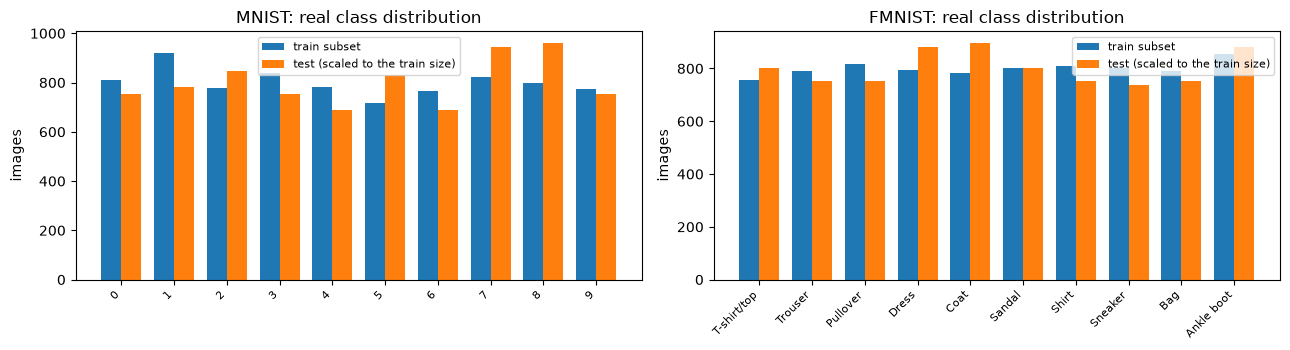

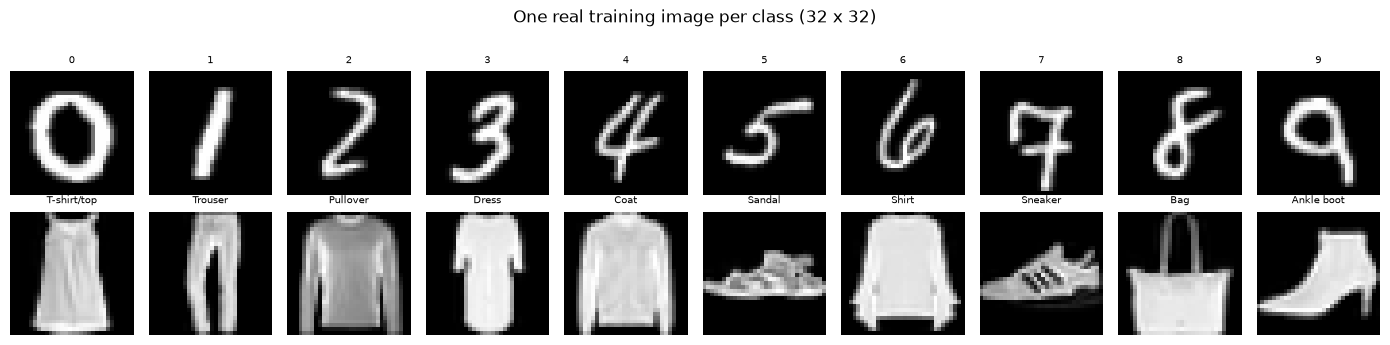

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, name in zip(axes, DATASETS):
    d = DATA[name]
    w = 0.38; xs = np.arange(10)
    ax.bar(xs - w / 2, np.bincount(d["ytr"].numpy(), minlength=10), w, label="train subset")
    ax.bar(xs + w / 2, np.bincount(d["yte"].numpy(), minlength=10) * (len(d["ytr"]) / max(1, len(d["yte"]))), w,
           label="test (scaled to the train size)")
    ax.set_xticks(xs); ax.set_xticklabels(CLASS_NAMES[name], rotation=45, ha="right", fontsize=8)
    ax.set_title(f"{name}: real class distribution"); ax.set_ylabel("images"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 10, figsize=(14, 3.4))
for r_, name in enumerate(DATASETS):
    d = DATA[name]
    for c in range(10):
        i = int((d["ytr"] == c).nonzero()[0, 0])
        axes[r_, c].imshow(d["Xtr"][i].reshape(32, 32), cmap="gray"); axes[r_, c].axis("off")
        axes[r_, c].set_title(CLASS_NAMES[name][c], fontsize=7)
plt.suptitle("One real training image per class (32 x 32)", y=1.02); plt.tight_layout(); plt.show()

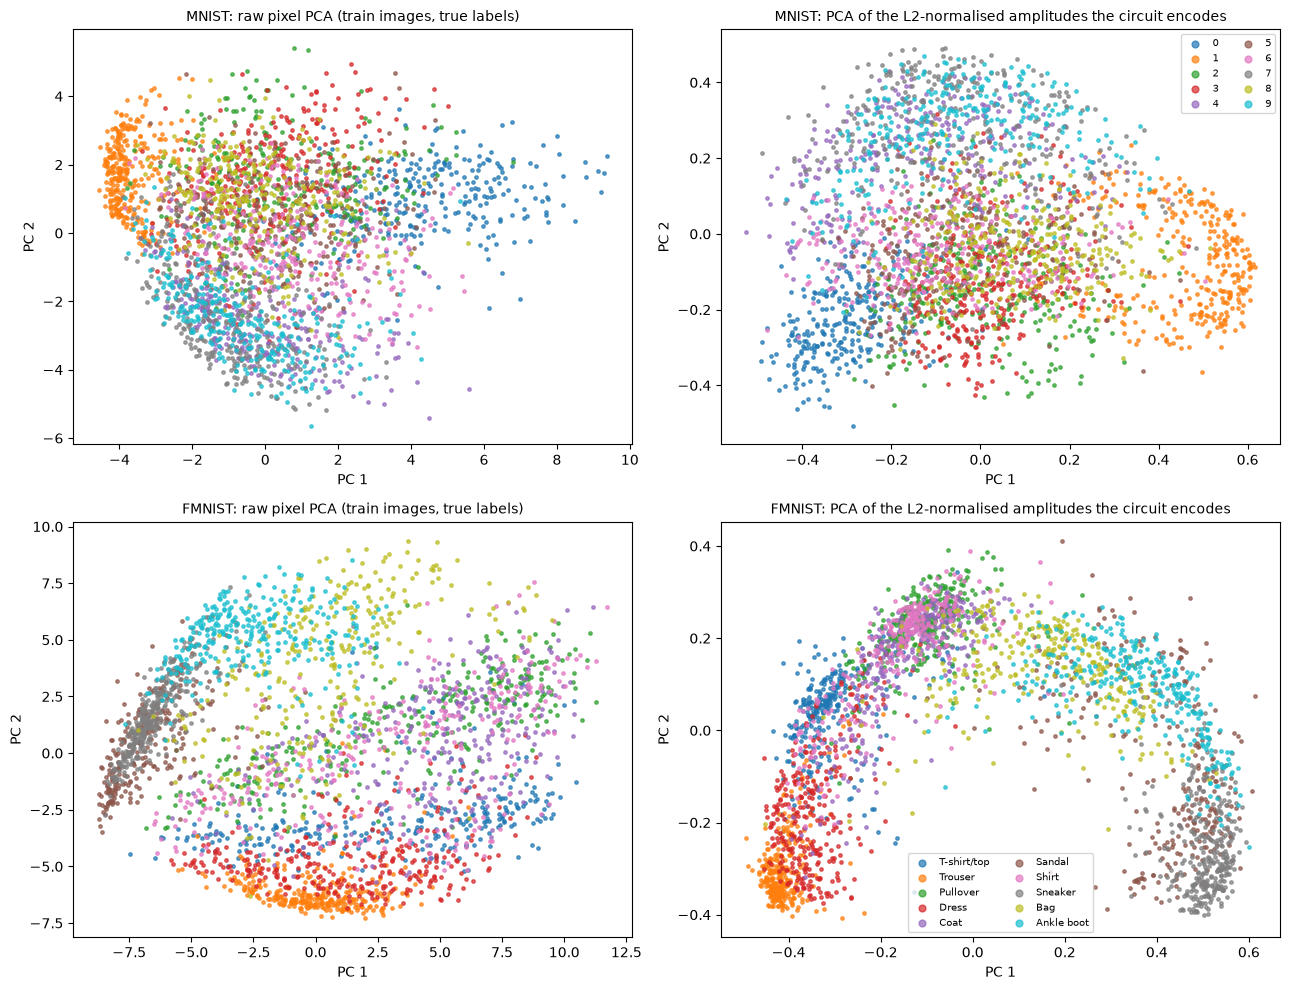

In [8]:
CMAP = plt.get_cmap("tab10")
def scatter_pca(ax, Z, y, names, title):
    for c in range(10):
        m = y == c
        ax.scatter(Z[m, 0], Z[m, 1], s=6, color=CMAP(c), label=names[c], alpha=0.7)
    ax.set_title(title, fontsize=10); ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2")

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for r_, name in enumerate(DATASETS):
    d = DATA[name]
    X = d["Xtr"].numpy()[:3000]; y = d["ytr"].numpy()[:3000]
    pca = PCA(n_components=2, random_state=SEED).fit(d["Xtr"].numpy())             # fitted on the training subset only
    scatter_pca(axes[r_, 0], pca.transform(X), y, CLASS_NAMES[name], f"{name}: raw pixel PCA (train images, true labels)")
    Xn = d["Xtr"].numpy(); Xn = Xn / np.linalg.norm(Xn, axis=1, keepdims=True)
    pca_n = PCA(n_components=2, random_state=SEED).fit(Xn)
    scatter_pca(axes[r_, 1], pca_n.transform(Xn[:3000]), y, CLASS_NAMES[name], f"{name}: PCA of the L2-normalised amplitudes the circuit encodes")
    axes[r_, 1].legend(fontsize=7, markerscale=2, ncol=2, loc="best")
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

Three PennyLane circuits are executed in this notebook: (1) the **VQC classifier**, (2) the **QAE training circuit with the SWAP test**
(maximising `<Z>` of the ancilla) and (3) the **QAE reconstruction circuit** (encoder, swap of the trash qubits with the reference
|0>, decoder = inverse encoder). Each is drawn with `qml.draw_mpl` from the real QNode. Because VQC-100 repeats the same layer 100 times
(2,001 gates), the picture shows the *same QNode function* with two layers; qubit count, depth and parameter count are printed for the
full-depth QNode, and the equivalence cell evaluates the full-depth QNodes against the fast torch simulator used in the training loops.

Assumptions where the paper omits circuit details: CNOT ring with range 1 (including 9 -> 0), 1 trash qubit (the last wire, 9), reference qubit 10 in |0>, ancilla 11 for the SWAP test,
amplitude embedding with normalisation, decoder acting on the 10 wires that hold the 9 latent qubits and the reference qubit after the swap.

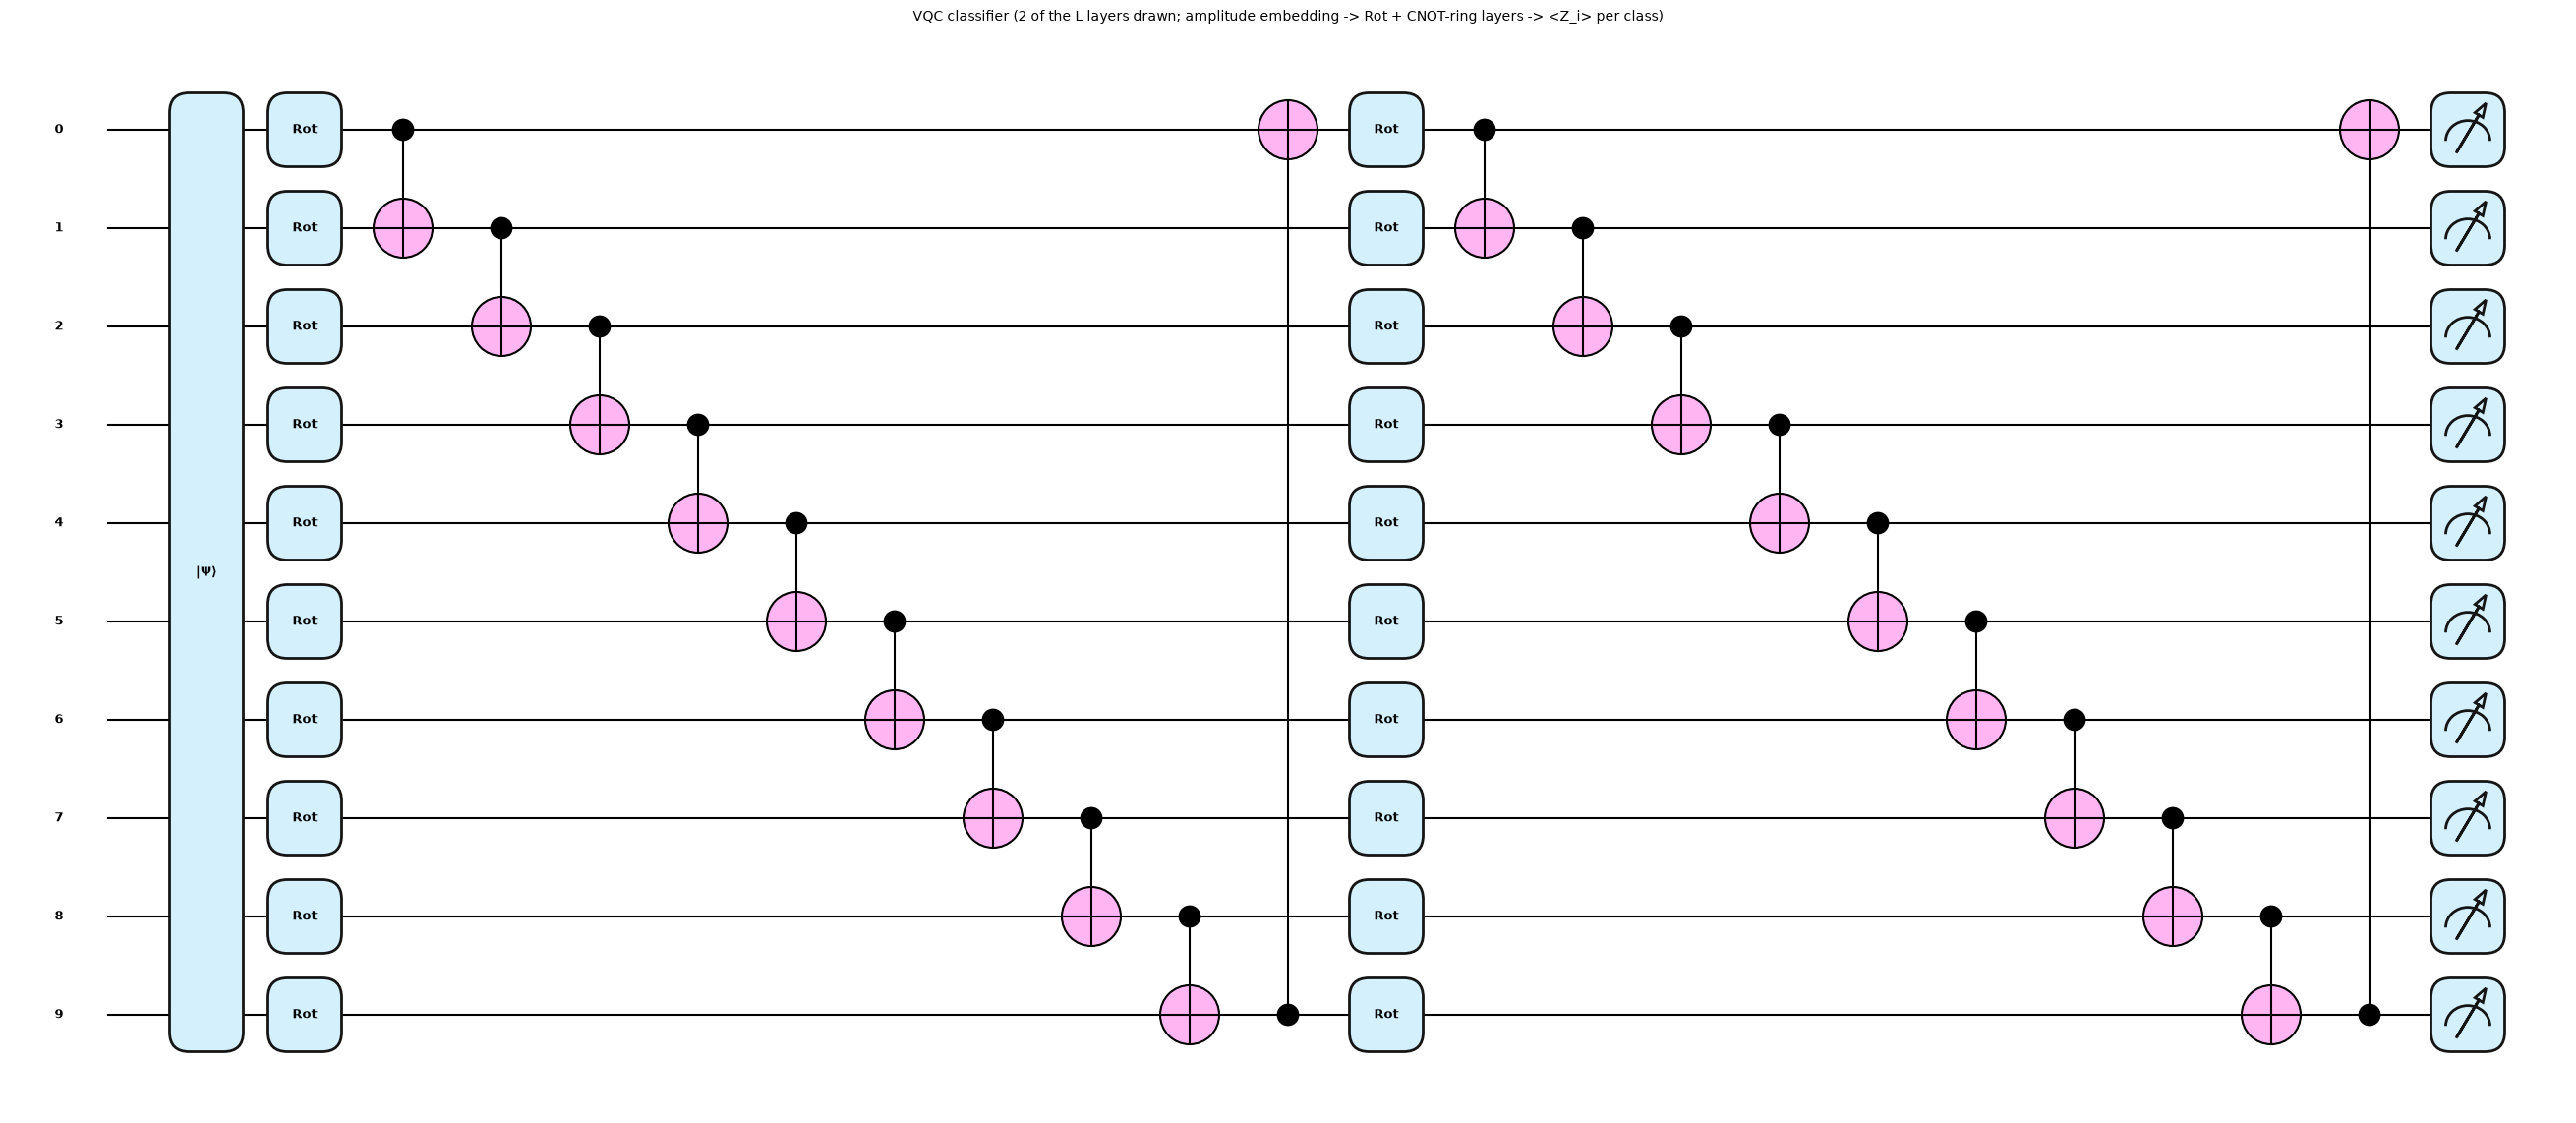

In [9]:
dev_vqc = qml.device("default.qubit", wires=N_QUBITS)
@qml.qnode(dev_vqc, interface="torch")
def vqc_qnode(x, weights):
    qml.AmplitudeEmbedding(x, wires=range(N_QUBITS), normalize=True)
    qml.StronglyEntanglingLayers(weights, wires=range(N_QUBITS), ranges=[1] * weights.shape[0])   # CHOICE: neighbouring CNOTs
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]

T_WIRES = list(range(N_QUBITS - N_TRASH, N_QUBITS))               # trash wire(s): the last N_TRASH wires
R_WIRES = list(range(N_QUBITS, N_QUBITS + N_TRASH))               # reference wire(s) in |0>
ANC = N_QUBITS + N_TRASH                                          # SWAP-test ancilla
dev_qae = qml.device("default.qubit", wires=N_QUBITS + N_TRASH + 1)

@qml.qnode(dev_qae, interface="torch")
def qae_train_qnode(x, weights):
    qml.AmplitudeEmbedding(x, wires=range(N_QUBITS), normalize=True)
    qml.StronglyEntanglingLayers(weights, wires=range(N_QUBITS), ranges=[1] * weights.shape[0])   # encoder U(theta)
    qml.Hadamard(wires=ANC)                                                                       # SWAP test between trash and |0..0>
    for t_, r_ in zip(T_WIRES, R_WIRES):
        qml.CSWAP(wires=[ANC, t_, r_])
    qml.Hadamard(wires=ANC)
    return qml.expval(qml.PauliZ(ANC))                                                            # <Z> = fidelity, loss = 1 - <Z>

@qml.qnode(dev_qae, interface="torch")
def qae_recon_qnode(x, weights):
    qml.AmplitudeEmbedding(x, wires=range(N_QUBITS), normalize=True)
    qml.StronglyEntanglingLayers(weights, wires=range(N_QUBITS), ranges=[1] * weights.shape[0])   # encoder
    for t_, r_ in zip(T_WIRES, R_WIRES):
        qml.SWAP(wires=[t_, r_])                                                                  # trash out, reference |0> in
    qml.adjoint(qml.StronglyEntanglingLayers)(weights, wires=range(N_QUBITS), ranges=[1] * weights.shape[0])   # decoder = U^dagger
    return qml.probs(wires=range(N_QUBITS))                                                       # reconstructed image probabilities

x_demo = DATA[DATASETS[0]]["Xte"][0].double()
W_demo = torch.rand(2, N_QUBITS, 3).double() * 2 * math.pi
fig, ax = qml.draw_mpl(vqc_qnode, level="device", style="pennylane", fontsize=9)(x_demo, W_demo)
fig.suptitle("VQC classifier (2 of the L layers drawn; amplitude embedding -> Rot + CNOT-ring layers -> <Z_i> per class)", y=1.02, fontsize=10)
plt.show()

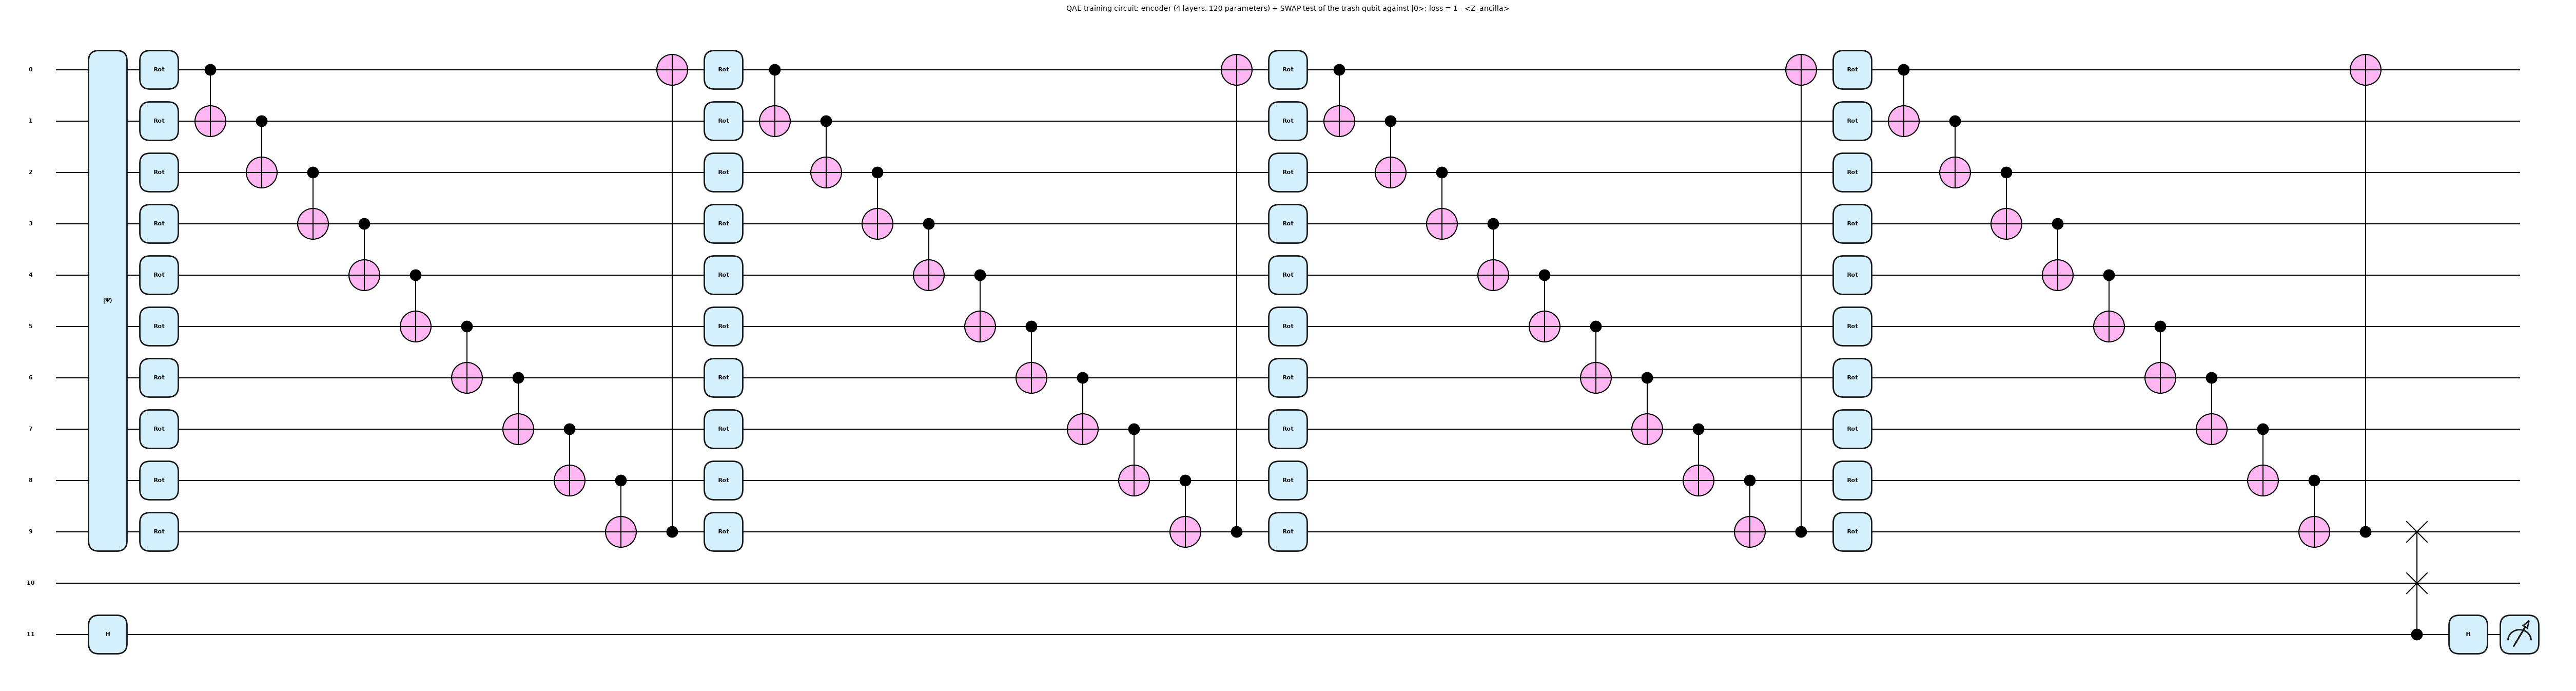

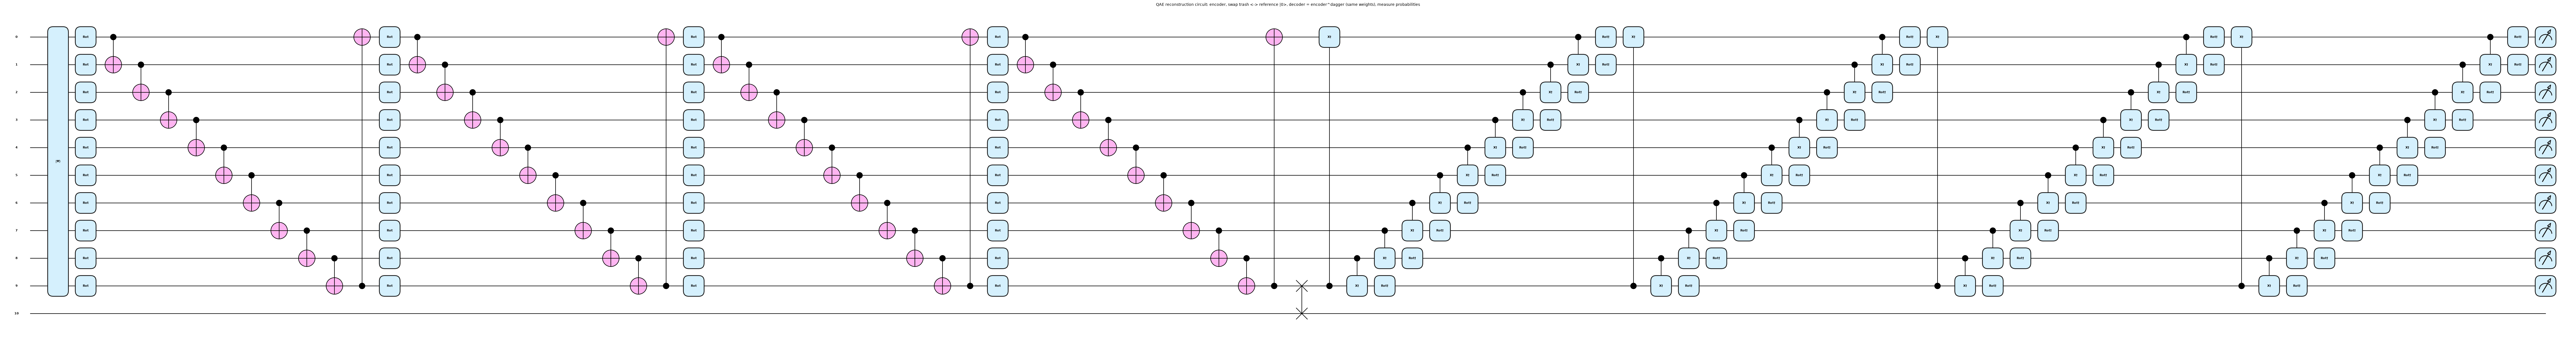

In [10]:
Wq_demo = torch.rand(QAE_LAYERS, N_QUBITS, 3).double() * 2 * math.pi
fig, ax = qml.draw_mpl(qae_train_qnode, level="device", style="pennylane", fontsize=8)(x_demo, Wq_demo)
fig.suptitle("QAE training circuit: encoder (4 layers, 120 parameters) + SWAP test of the trash qubit against |0>; loss = 1 - <Z_ancilla>", y=1.02, fontsize=10)
plt.show()
fig, ax = qml.draw_mpl(qae_recon_qnode, level="device", style="pennylane", fontsize=8)(x_demo, Wq_demo)
fig.suptitle("QAE reconstruction circuit: encoder, swap trash <-> reference |0>, decoder = encoder^dagger (same weights), measure probabilities", y=1.02, fontsize=10)
plt.show()

In [11]:
def circuit_report(qnode, args, label, n_params):
    tape = qml.workflow.construct_batch(qnode, level="device")(*args)[0][0]
    ops = tape.operations
    print(f"{label}: qubits = {len(tape.wires)}, gates = {len(ops)}, depth = {tape.graph.get_depth()}, trainable parameters = {n_params}")

for L in VQC_LAYERS_LIST:
    circuit_report(vqc_qnode, (x_demo, torch.rand(L, N_QUBITS, 3).double()), f"VQC-{L}", L * N_QUBITS * 3)
circuit_report(qae_train_qnode, (x_demo, Wq_demo), "QAE training circuit (encoder + SWAP test)", Wq_demo.numel())
circuit_report(qae_recon_qnode, (x_demo, Wq_demo), "QAE reconstruction circuit (encoder + swap + decoder)", Wq_demo.numel())
print("(the decoder re-uses the encoder weights, so the QAE has", Wq_demo.numel(), "parameters in total; paper: 120)")

VQC-20: qubits = 10, gates = 401, depth = 221, trainable parameters = 600
QAE training circuit (encoder + SWAP test): qubits = 12, gates = 84, depth = 47, trainable parameters = 120
QAE reconstruction circuit (encoder + swap + decoder): qubits = 11, gates = 162, depth = 90, trainable parameters = 120
(the decoder re-uses the encoder weights, so the QAE has 120 parameters in total; paper: 120)


In [12]:
# Equivalence check: PennyLane QNodes (reference) versus the fast torch simulator used for training and attacks.
torch.manual_seed(SEED)
L_chk = VQC_LAYERS_LIST[0]
W_chk = torch.rand(L_chk, N_QUBITS, 3) * 2 * math.pi
Wq_chk = torch.rand(QAE_LAYERS, N_QUBITS, 3) * 2 * math.pi
x_chk = DATA[DATASETS[0]]["Xte"][:2]

ref_logits = torch.stack([torch.stack(vqc_qnode(x_chk[i].double(), W_chk.double())) for i in range(2)]).float()
err_vqc = (ref_logits - vqc_logits(x_chk, W_chk)).abs().max().item()
rec_fast, fid_fast = qae_reconstruct(x_chk, Wq_chk, N_TRASH)
err_fid = max(abs(float(qae_train_qnode(x_chk[i].double(), Wq_chk.double())) - fid_fast[i].item()) for i in range(2))
err_rec = max((qae_recon_qnode(x_chk[i].double(), Wq_chk.double()).float() - rec_fast[i] ** 2).abs().max().item() for i in range(2))
print(f"max |PennyLane - fast simulator|: VQC-{L_chk} logits {err_vqc:.2e} | SWAP-test fidelity {err_fid:.2e} | QAE reconstruction probabilities {err_rec:.2e}")
assert err_vqc < 1e-4 and err_fid < 1e-4 and err_rec < 1e-5, "fast simulator disagrees with the PennyLane circuits"
print("equivalence OK")

max |PennyLane - fast simulator|: VQC-20 logits 2.27e-07 | SWAP-test fidelity 3.68e-08 | QAE reconstruction probabilities 7.45e-09
equivalence OK


## 3. Training the VQC (the model under attack)

Adam on the cross-entropy of the ten Pauli-Z expectation values. The paper trains 20 epochs at learning rate 0.005, batch 256 on all
60,000 images; the budget used here is in the configuration cell (fewer images / epochs, larger learning rate, `# CHOICE`), so the
clean accuracy will be somewhat lower than the paper's. We keep the validation accuracy per epoch.

In [13]:
def evaluate_logits(fn, X, chunk=500):
    with torch.no_grad():
        return torch.cat([fn(X[i:i + chunk]) for i in range(0, len(X), chunk)])

def train_vqc(d, n_layers, epochs, bs, lr, seed, tag):
    g = torch.Generator().manual_seed(seed)
    W = (torch.rand(n_layers, N_QUBITS, 3, generator=g) * 2 * math.pi).requires_grad_()    # CHOICE: uniform [0, 2pi) init
    opt = torch.optim.Adam([W], lr=lr)
    hist, t0 = [], time.time()
    for ep in range(epochs):
        perm = torch.randperm(len(d["Xtr"]), generator=g)
        losses = []
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            loss = F.cross_entropy(vqc_logits(d["Xtr"][idx], W), d["ytr"][idx])
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item())
        va = (evaluate_logits(lambda x: vqc_logits(x, W.detach()), d["Xva"]).argmax(1) == d["yva"]).float().mean().item()
        hist.append((ep + 1, float(np.mean(losses)), va))
        print(f"[{tag}] epoch {ep+1}/{epochs}  loss {np.mean(losses):.4f}  val acc {va*100:.2f}%  ({time.time()-t0:.0f}s)", flush=True)
    return W.detach(), hist

VQC, VQC_HIST = {}, {}
for name in DATASETS:
    for L in VQC_LAYERS_LIST:
        VQC[(name, L)], VQC_HIST[(name, L)] = train_vqc(DATA[name], L, VQC_EPOCHS, VQC_BS, VQC_LR, SEED, f"{name} VQC-{L}")

[MNIST VQC-20] epoch 1/3  loss 2.2017  val acc 73.67%  (42s)


[MNIST VQC-20] epoch 2/3  loss 2.1625  val acc 72.00%  (82s)


[MNIST VQC-20] epoch 3/3  loss 2.1543  val acc 76.33%  (127s)


[FMNIST VQC-20] epoch 1/3  loss 2.1659  val acc 49.00%  (39s)


[FMNIST VQC-20] epoch 2/3  loss 2.1221  val acc 55.67%  (81s)


[FMNIST VQC-20] epoch 3/3  loss 2.1139  val acc 57.33%  (124s)


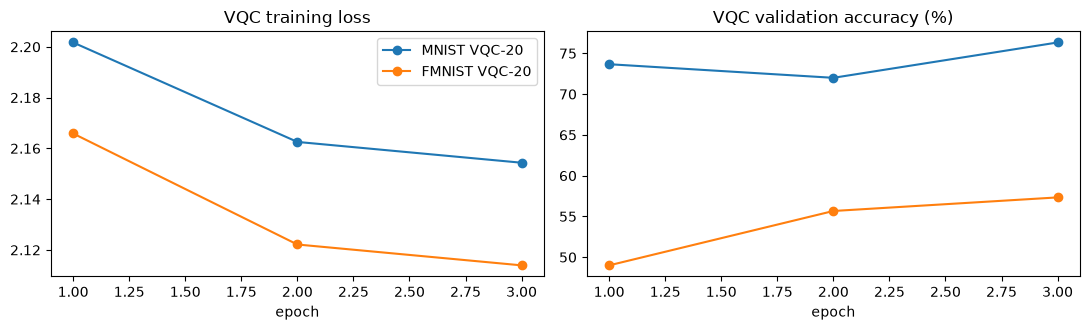

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for (name, L), h in VQC_HIST.items():
    h = np.array(h)
    axes[0].plot(h[:, 0], h[:, 1], marker="o", label=f"{name} VQC-{L}"); axes[1].plot(h[:, 0], h[:, 2] * 100, marker="o", label=f"{name} VQC-{L}")
axes[0].set_title("VQC training loss"); axes[0].set_xlabel("epoch"); axes[1].set_title("VQC validation accuracy (%)"); axes[1].set_xlabel("epoch")
axes[0].legend(); plt.tight_layout(); plt.show()

## 4. Classical baselines on the identical inputs

For context, a random forest and an RBF-kernel SVM are trained on exactly the inputs the VQC sees (the 1024 amplitudes, i.e. the
L2-normalised pixel vectors) and scored on the same clean test images. They are fitted on (at most) 5,000 training images to keep the cell short.
The paper's classical comparison is the CAE *defence* (section 6), not a classifier.

In [15]:
rows = []
for name in DATASETS:
    d = DATA[name]
    nrm = lambda X: (X / X.norm(dim=1, keepdim=True)).numpy()
    n_fit = min(5000, len(d["Xtr"]))
    Xa, ya = nrm(d["Xtr"][:n_fit]), d["ytr"][:n_fit].numpy()
    Xt, yt = nrm(d["Xte"]), d["yte"].numpy()
    t0 = time.time(); rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=2).fit(Xa, ya)
    rows.append((name, "RandomForest(200)", (rf.predict(Xt) == yt).mean() * 100, time.time() - t0))
    t0 = time.time(); sv = SVC(kernel="rbf", C=10, random_state=SEED).fit(Xa, ya)
    rows.append((name, "SVC(rbf, C=10)", (sv.predict(Xt) == yt).mean() * 100, time.time() - t0))
    for L in VQC_LAYERS_LIST:
        acc = (evaluate_logits(lambda x: vqc_logits(x, VQC[(name, L)]), d["Xte"]).argmax(1) == d["yte"]).float().mean().item() * 100
        rows.append((name, f"VQC-{L} (this notebook)", acc, np.nan))
print(pd.DataFrame(rows, columns=["dataset", "model", "clean test accuracy (%)", "fit time (s)"]).round(2).to_string(index=False))

dataset                  model  clean test accuracy (%)  fit time (s)
  MNIST      RandomForest(200)                     94.4         15.81
  MNIST         SVC(rbf, C=10)                     97.4         25.57
  MNIST VQC-20 (this notebook)                     68.6           NaN
 FMNIST      RandomForest(200)                     85.8         26.83
 FMNIST         SVC(rbf, C=10)                     85.4         23.40
 FMNIST VQC-20 (this notebook)                     61.2           NaN


## 5. Training the quantum autoencoder

The encoder is `QAE_LAYERS = 4` strongly-entangling layers on the 10 amplitude-embedded qubits (120 parameters). The loss is
`1 - <Z>`, with `<Z>` the SWAP-test fidelity between the trash qubit and the reference |0> (computed exactly as the
probability that the trash qubit reads 0, which the equivalence cell verified against the explicit SWAP-test circuit). Only clean training images are used; no adversarial example
enters the training of the QAE or of the VQC.

In [16]:
def train_qae(d, epochs, bs, lr, seed, tag):
    g = torch.Generator().manual_seed(seed)
    Wq = (torch.rand(QAE_LAYERS, N_QUBITS, 3, generator=g) * 2 * math.pi).requires_grad_()
    opt = torch.optim.Adam([Wq], lr=lr)
    hist, t0 = [], time.time()
    for ep in range(epochs):
        perm = torch.randperm(len(d["Xtr"]), generator=g)
        losses = []
        for i in range(0, len(perm), bs):
            _, fid = qae_encode(d["Xtr"][perm[i:i + bs]], Wq, N_TRASH)
            loss = 1 - fid.mean()                                                     # L = 1 - <Z>
            opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
        hist.append((ep + 1, float(np.mean(losses))))
        print(f"[{tag}] epoch {ep+1}/{epochs}  loss 1-<Z> = {np.mean(losses):.4f}  ({time.time()-t0:.0f}s)", flush=True)
    return Wq.detach(), hist

QAE, QAE_HIST = {}, {}
for name in DATASETS:
    QAE[name], QAE_HIST[name] = train_qae(DATA[name], QAE_EPOCHS, QAE_BS, QAE_LR, SEED, f"{name} QAE")
print("QAE trainable parameters:", QAE[DATASETS[0]].numel(), "(paper: 120)")

[MNIST QAE] epoch 1/4  loss 1-<Z> = 0.1889  (9s)


[MNIST QAE] epoch 2/4  loss 1-<Z> = 0.1382  (22s)


[MNIST QAE] epoch 3/4  loss 1-<Z> = 0.1144  (31s)


[MNIST QAE] epoch 4/4  loss 1-<Z> = 0.0307  (42s)


[FMNIST QAE] epoch 1/4  loss 1-<Z> = 0.1129  (9s)


[FMNIST QAE] epoch 2/4  loss 1-<Z> = 0.0610  (19s)


[FMNIST QAE] epoch 3/4  loss 1-<Z> = 0.0586  (29s)


[FMNIST QAE] epoch 4/4  loss 1-<Z> = 0.0438  (40s)


QAE trainable parameters: 120 (paper: 120)


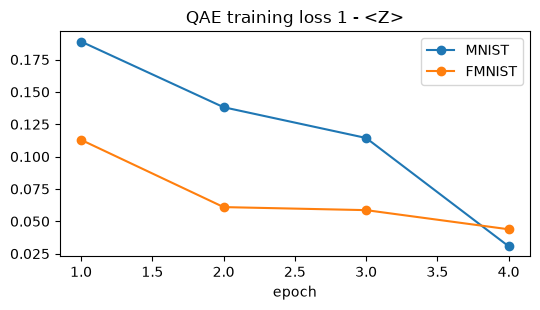

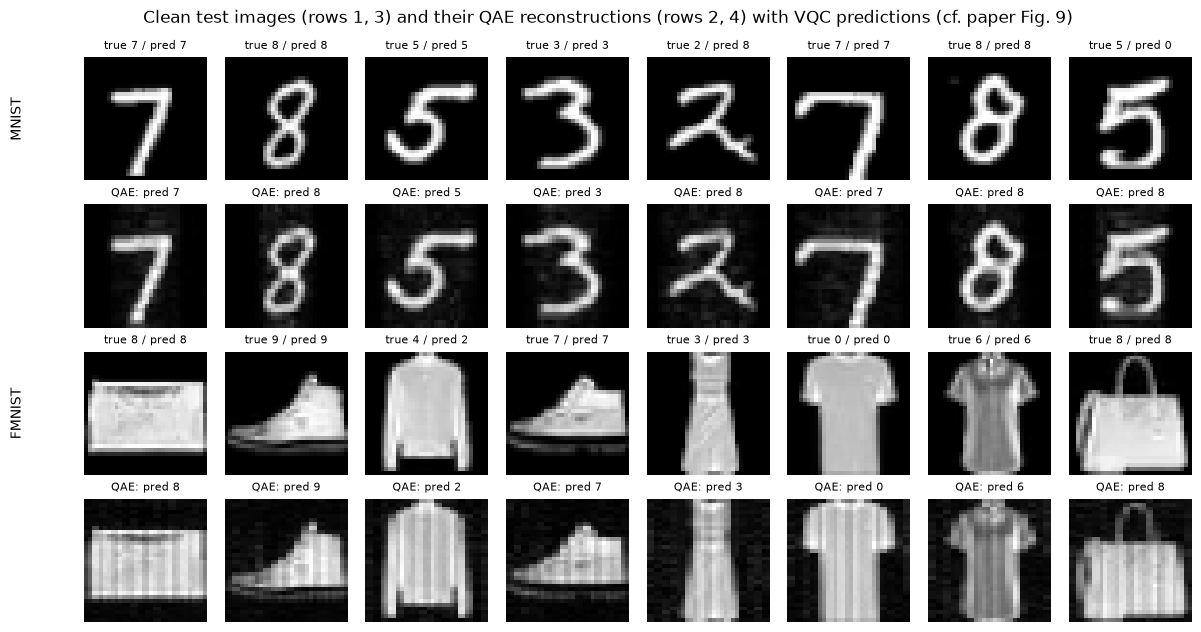

In [17]:
fig, ax = plt.subplots(figsize=(5.5, 3.2))
for name, h in QAE_HIST.items():
    h = np.array(h); ax.plot(h[:, 0], h[:, 1], marker="o", label=name)
ax.set_title("QAE training loss 1 - <Z>"); ax.set_xlabel("epoch"); ax.legend(); plt.tight_layout(); plt.show()

# Fig. 9 analogue: clean images, QAE reconstructions, and the VQC prediction on both
L0 = VQC_LAYERS_LIST[0]
fig, axes = plt.subplots(4, 8, figsize=(12, 6.4))
for k, name in enumerate(DATASETS):
    d = DATA[name]; X = d["Xte"][:8]; y = d["yte"][:8]
    with torch.no_grad():
        xr, fid = qae_reconstruct(X, QAE[name], N_TRASH)
        p0 = vqc_logits(X, VQC[(name, L0)]).argmax(1); p1 = vqc_logits(xr, VQC[(name, L0)]).argmax(1)
    for j in range(8):
        axes[2*k, j].imshow(X[j].reshape(32, 32), cmap="gray"); axes[2*k, j].set_title(f"true {y[j].item()} / pred {p0[j].item()}", fontsize=8)
        axes[2*k+1, j].imshow(xr[j].reshape(32, 32), cmap="gray"); axes[2*k+1, j].set_title(f"QAE: pred {p1[j].item()}", fontsize=8)
        axes[2*k, j].axis("off"); axes[2*k+1, j].axis("off")
    axes[2*k, 0].text(-0.6, 0.5, name, transform=axes[2*k, 0].transAxes, rotation=90, va="center")
plt.suptitle("Clean test images (rows 1, 3) and their QAE reconstructions (rows 2, 4) with VQC predictions (cf. paper Fig. 9)"); plt.tight_layout(); plt.show()

## 6. The classical autoencoder baseline (CAE)

The paper compares with a convolutional autoencoder (convolution + ReLU layers and a final linear layer, 91,424 parameters),
trained for fairness on **clean** images only. The exact architecture of the cited work is not given, so we use a small convolutional autoencoder
of comparable size (three strided convolutions, a 24-dimensional linear bottleneck, three transposed convolutions, sigmoid output), trained with Adam, lr 0.001, batch 128 and a pixel-wise binary cross-entropy loss
(`# CHOICE`; an MSE loss stalled on the constant mean image in our first runs). Its parameter count is printed and is used in the comparison instead of the paper's number.

In [18]:
class CAE(nn.Module):
    def __init__(self, z=24):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(1, 16, 3, 2, 1), nn.ReLU(), nn.Conv2d(16, 32, 3, 2, 1), nn.ReLU(),
                                 nn.Conv2d(32, 64, 3, 2, 1), nn.ReLU(), nn.Flatten(), nn.Linear(64 * 16, z))
        self.fc = nn.Sequential(nn.ReLU(), nn.Linear(z, 64 * 16), nn.ReLU())
        self.dec = nn.Sequential(nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(), nn.ConvTranspose2d(32, 16, 4, 2, 1), nn.ReLU(),
                                 nn.ConvTranspose2d(16, 1, 4, 2, 1))
    def logits(self, x):
        b = x.shape[0]
        h = self.fc(self.enc(x.reshape(b, 1, 32, 32))).reshape(b, 64, 4, 4)
        return self.dec(h).reshape(b, -1)
    def forward(self, x):
        return torch.sigmoid(self.logits(x))

def train_cae(d, epochs, bs, lr, seed, tag):
    torch.manual_seed(seed)
    m = CAE(); opt = torch.optim.Adam(m.parameters(), lr=lr)
    g = torch.Generator().manual_seed(seed); t0 = time.time()
    for ep in range(epochs):
        perm = torch.randperm(len(d["Xtr"]), generator=g); ls = []
        for i in range(0, len(perm), bs):
            x = d["Xtr"][perm[i:i + bs]]
            loss = F.binary_cross_entropy_with_logits(m.logits(x), x); opt.zero_grad(); loss.backward(); opt.step(); ls.append(loss.item())
        print(f"[{tag}] epoch {ep+1}/{epochs}  BCE {np.mean(ls):.5f}  ({time.time()-t0:.0f}s)", flush=True)
    return m.eval()

CAES = {name: train_cae(DATA[name], CAE_EPOCHS, CAE_BS, CAE_LR, SEED, f"{name} CAE") for name in DATASETS}
n_cae = sum(p.numel() for p in CAES[DATASETS[0]].parameters())
print(f"CAE parameters: {n_cae:,} (paper: 91,424) | QAE parameters: {QAE[DATASETS[0]].numel()} (paper: 120)")

[MNIST CAE] epoch 1/8  BCE 0.45250  (11s)


[MNIST CAE] epoch 2/8  BCE 0.26641  (24s)


[MNIST CAE] epoch 3/8  BCE 0.25735  (38s)


[MNIST CAE] epoch 4/8  BCE 0.22402  (50s)


[MNIST CAE] epoch 5/8  BCE 0.18627  (63s)


...

[FMNIST CAE] epoch 5/8  BCE 0.32126  (93s)


[FMNIST CAE] epoch 6/8  BCE 0.31774  (109s)


[FMNIST CAE] epoch 7/8  BCE 0.31493  (126s)


[FMNIST CAE] epoch 8/8  BCE 0.31274  (138s)


CAE parameters: 114,761 (paper: 91,424) | QAE parameters: 120 (paper: 120)


## 7. The attacks: FGSM and PGD against the undefended VQC

`FGSM: x_adv = clip(x + eps sign(grad_x L))`; `PGD`: `PGD_STEPS` iterations of step `2.5 eps / steps`, each followed by the projection onto the
l-infinity ball of radius eps around the clean image and onto [0, 1] (the paper's Eq. 1-2; step size and iteration count are `# CHOICE`).
The loss is the cross-entropy of the VQC's logits and the gradient is taken through the amplitude normalisation and all circuit layers.
The adversary attacks the **VQC alone**; it does not know about the autoencoder.

In [19]:
def input_grad(x, y, W):
    x = x.clone().requires_grad_(True)
    loss = F.cross_entropy(vqc_logits(x, W), y, reduction="sum")
    return torch.autograd.grad(loss, x)[0]

def make_attacks(X, y, W, eps_list, pgd_steps, chunk=ATTACK_CHUNK, tag=""):
    W = W.detach()
    adv = {("FGSM", e): [] for e in eps_list}; adv.update({("PGD", e): [] for e in eps_list})
    t0 = time.time()
    for i in range(0, len(X), chunk):
        x0, yy = X[i:i + chunk], y[i:i + chunk]
        g0 = input_grad(x0, yy, W).sign()
        for e in eps_list:
            adv[("FGSM", e)].append((x0 + e * g0).clamp(0, 1))
        for e in eps_list:
            a = 2.5 * e / pgd_steps; xa = x0.clone()
            for _ in range(pgd_steps):
                xa = xa + a * input_grad(xa, yy, W).sign()
                xa = torch.min(torch.max(xa, x0 - e), x0 + e).clamp(0, 1)
            adv[("PGD", e)].append(xa)
        print(f"[{tag}] attacked {min(i + chunk, len(X))}/{len(X)} images ({time.time()-t0:.0f}s)", flush=True)
    return {k: torch.cat(v).detach() for k, v in adv.items()}

ADV = {}
for name in DATASETS:
    for L in VQC_LAYERS_LIST:
        d = DATA[name]
        ADV[(name, L)] = make_attacks(d["Xte"], d["yte"], VQC[(name, L)], EPS_LIST, PGD_STEPS, tag=f"{name} VQC-{L}")

[MNIST VQC-20] attacked 250/500 images (15s)


[MNIST VQC-20] attacked 500/500 images (27s)


[FMNIST VQC-20] attacked 250/500 images (17s)


[FMNIST VQC-20] attacked 500/500 images (36s)


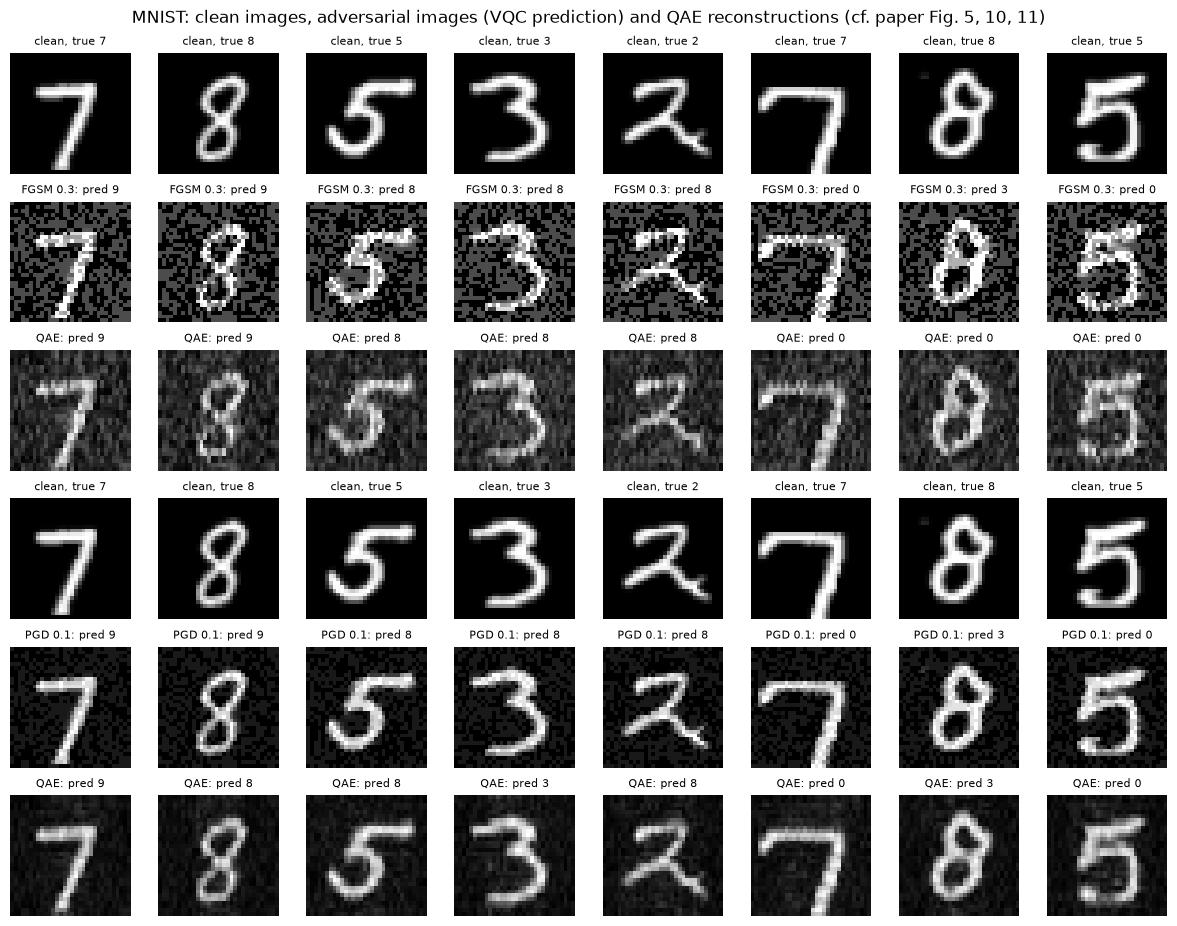

In [20]:
# Figs. 5, 10, 11 analogues: perturbed images, VQC prediction without defence, and the QAE reconstruction
name = DATASETS[0]; L0 = VQC_LAYERS_LIST[0]; d = DATA[name]
fig, axes = plt.subplots(6, 8, figsize=(12, 9.4))
for r0, (att, e) in enumerate([("FGSM", 0.30), ("PGD", 0.10)]):
    Xa = ADV[(name, L0)][(att, e)][:8]; y = d["yte"][:8]
    with torch.no_grad():
        pa = vqc_logits(Xa, VQC[(name, L0)]).argmax(1); xr, _ = qae_reconstruct(Xa, QAE[name], N_TRASH)
        pr = vqc_logits(xr, VQC[(name, L0)]).argmax(1)
    for j in range(8):
        axes[3*r0, j].imshow(d["Xte"][j].reshape(32, 32), cmap="gray"); axes[3*r0, j].set_title(f"clean, true {y[j].item()}", fontsize=8)
        axes[3*r0+1, j].imshow(Xa[j].reshape(32, 32), cmap="gray"); axes[3*r0+1, j].set_title(f"{att} {e}: pred {pa[j].item()}", fontsize=8)
        axes[3*r0+2, j].imshow(xr[j].reshape(32, 32), cmap="gray"); axes[3*r0+2, j].set_title(f"QAE: pred {pr[j].item()}", fontsize=8)
        for k in range(3): axes[3*r0+k, j].axis("off")
plt.suptitle(f"{name}: clean images, adversarial images (VQC prediction) and QAE reconstructions (cf. paper Fig. 5, 10, 11)"); plt.tight_layout(); plt.show()

## 8. Calibrating the QAE++ confidence threshold

On the clean **validation** images (never used for training or testing): the fidelity threshold is the 1st percentile of the
validation encoding fidelities minus `delta = 0.05`; the logit threshold is the mean logit difference (top-1 minus top-2 logit) of the
*wrongly classified* validation images minus `gamma = 0.01`; `T = <Z>_T + l_T / 2` (paper Eq. 8-11). A sample is accepted when
`C = <Z>_x + l / 2 >= T`.

In [21]:
def top2_diff(lg):
    t = lg.topk(2, dim=1).values
    return t[:, 0] - t[:, 1]

def qae_pipeline(X, W, Wq):
    with torch.no_grad():
        xr, fid = qae_reconstruct(X, Wq, N_TRASH)
        lg = vqc_logits(xr, W)
    return lg, fid

def calibrate(name, L):
    d, W, Wq = DATA[name], VQC[(name, L)], QAE[name]
    outs = [qae_pipeline(d["Xva"][i:i + 500], W, Wq) for i in range(0, len(d["Xva"]), 500)]
    lg, fid = torch.cat([o[0] for o in outs]), torch.cat([o[1] for o in outs])
    wrong = lg.argmax(1) != d["yva"]
    fid_T = np.percentile(fid.numpy(), 1) - DELTA
    l_T = top2_diff(lg)[wrong].mean().item() - GAMMA
    return dict(fid_T=float(fid_T), l_T=float(l_T), T=float(fid_T + l_T / 2), val_acc=1 - wrong.float().mean().item(),
                val_fid_mean=fid.mean().item(), val_ld_mean=top2_diff(lg).mean().item())

THRESH = {(n, L): calibrate(n, L) for n in DATASETS for L in VQC_LAYERS_LIST}
print(pd.DataFrame(THRESH).T.round(4).to_string())

            fid_T     l_T       T  val_acc  val_fid_mean  val_ld_mean
MNIST  20  0.8869  0.0247  0.8992     0.73        0.9741       0.0784
FMNIST 20  0.8668  0.0251  0.8793     0.55        0.9746       0.0606


## 9. Evaluating the four defences (the paper's Table I, Table II and Fig. 12)

For every attack and every epsilon the adversarial test images go through: *no defence* (VQC directly), the *CAE* (reconstruct, then VQC), the
*QAE* (reconstruct, then VQC) and *QAE++* (QAE + confidence-based rejection, scored as in the paper: an accepted sample counts if the VQC label is correct,
a rejected sample counts if the VQC label would have been wrong). We also record the four accept/reject counts of Table II and
the mean encoding fidelity and logit difference.

In [22]:
def evaluate_defences(Xa, y, name, L):
    W, Wq, cae, T = VQC[(name, L)], QAE[name], CAES[name], THRESH[(name, L)]["T"]
    with torch.no_grad():
        acc_none = (evaluate_logits(lambda x: vqc_logits(x, W), Xa).argmax(1) == y).float().mean().item()
        acc_cae = (evaluate_logits(lambda x: vqc_logits(cae(x), W), Xa).argmax(1) == y).float().mean().item()
    outs = [qae_pipeline(Xa[i:i + 500], W, Wq) for i in range(0, len(Xa), 500)]
    lg, fid = torch.cat([o[0] for o in outs]), torch.cat([o[1] for o in outs])
    correct = lg.argmax(1) == y
    ld = top2_diff(lg); C_ = fid + ld / 2; accept = C_ >= T
    res = dict(none=acc_none, cae=acc_cae, qae=correct.float().mean().item(),
               qaepp=((accept & correct) | (~accept & ~correct)).float().mean().item(),
               corr_accept=int((accept & correct).sum()), incorr_reject=int((~accept & ~correct).sum()),
               incorr_accept=int((accept & ~correct).sum()), corr_reject=int((~accept & correct).sum()),
               mean_fid=fid.mean().item(), mean_ld=ld.mean().item())
    return res

RESULTS = {}
for name in DATASETS:
    for L in VQC_LAYERS_LIST:
        d = DATA[name]; rows = []
        r0 = evaluate_defences(d["Xte"], d["yte"], name, L); rows.append(dict(attack="None", eps=0.0, **r0))
        for (att, e), Xa in ADV[(name, L)].items():
            rows.append(dict(attack=att, eps=e, **evaluate_defences(Xa, d["yte"], name, L)))
        df = pd.DataFrame(rows)
        for c in ["none", "cae", "qae", "qaepp"]:
            df[c] = df[c] * 100
        df["_o"] = df.attack.map({"None": 0, "FGSM": 1, "PGD": 2})
        df = df.sort_values(["_o", "eps"]).drop(columns="_o").reset_index(drop=True)
        RESULTS[(name, L)] = df
        print(f"\n===== {name}, VQC-{L}: accuracy (%) per defence (cf. paper Table I) =====")
        print(df[["attack", "eps", "none", "cae", "qae", "qaepp"]].round(2).to_string(index=False))


===== MNIST, VQC-20: accuracy (%) per defence (cf. paper Table I) =====
attack  eps  none  cae  qae  qaepp
  None 0.00  68.6 67.4 66.4   66.4
  FGSM 0.05  26.8 56.4 49.0   49.2
  FGSM 0.10   3.8 26.2 28.4   28.8
  FGSM 0.15   0.2 20.8 10.8   13.0
  FGSM 0.20   0.0 19.4  4.4   13.0
  FGSM 0.25   0.0 18.2  2.8   29.0
  FGSM 0.30   0.0 16.2  1.0   60.2
   PGD 0.05  26.2 56.4 48.6   48.8
   PGD 0.10   3.0 25.8 27.0   27.6
   PGD 0.15   0.2 20.6  9.4   11.6
   PGD 0.20   0.0 19.6  3.6   12.6
   PGD 0.25   0.0 17.4  1.8   30.4
   PGD 0.30   0.0 15.8  0.0   66.6



===== FMNIST, VQC-20: accuracy (%) per defence (cf. paper Table I) =====
attack  eps  none  cae  qae  qaepp
  None 0.00  61.2 59.2 60.8   61.0
  FGSM 0.05  19.0 55.0 31.0   31.2
  FGSM 0.10   5.4 39.8 15.8   17.4
  FGSM 0.15   0.4 30.8  7.2   15.0
  FGSM 0.20   0.0 26.0  2.4   17.8
  FGSM 0.25   0.0 20.6  0.6   25.2
  FGSM 0.30   0.0 15.6  0.0   36.6
   PGD 0.05  18.8 54.6 30.2   30.4
   PGD 0.10   4.0 38.8 15.0   16.4
   PGD 0.15   0.2 29.6  6.4   14.2
   PGD 0.20   0.0 23.8  2.0   16.2
   PGD 0.25   0.0 17.2  0.2   26.6
   PGD 0.30   0.0 12.4  0.0   40.2


In [23]:
print("Accept / reject counts of QAE++ (cf. paper Table II); the test set has", N_TEST, "images")
for (name, L), df in RESULTS.items():
    print(f"\n===== {name}, VQC-{L} =====")
    print(df[["attack", "eps", "corr_accept", "incorr_reject", "incorr_accept", "corr_reject", "mean_fid", "mean_ld"]]
          .rename(columns={"corr_accept": "Corr.Accept", "incorr_reject": "Incorr.Reject", "incorr_accept": "Incorr.Accept",
                           "corr_reject": "Corr.Reject", "mean_fid": "mean <Z>", "mean_ld": "mean logit diff"}).round(4).to_string(index=False))

Accept / reject counts of QAE++ (cf. paper Table II); the test set has 500 images

===== MNIST, VQC-20 =====
attack  eps  Corr.Accept  Incorr.Reject  Incorr.Accept  Corr.Reject  mean <Z>  mean logit diff
  None 0.00          332              0            168            0    0.9740           0.0752
  FGSM 0.05          245              1            254            0    0.9687           0.0547
  FGSM 0.10          142              2            356            0    0.9559           0.0435
  FGSM 0.15           54             11            435            0    0.9377           0.0417
  FGSM 0.20           21             44            434            1    0.9167           0.0420
  FGSM 0.25           14            131            355            0    0.8949           0.0391
  FGSM 0.30            2            299            196            3    0.8738           0.0357
   PGD 0.05          243              1            256            0    0.9688           0.0544
   PGD 0.10          135            

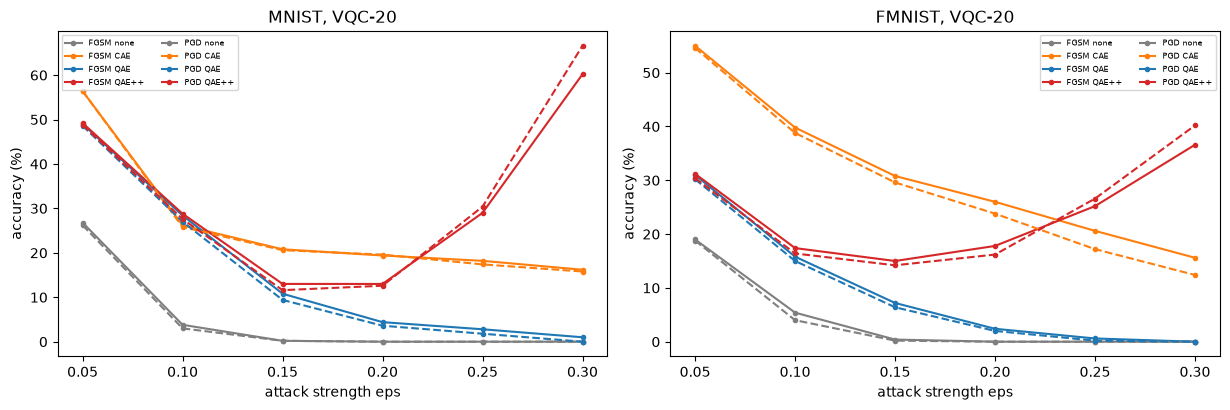

In [24]:
# Fig. 12 analogue: accuracy versus attack strength, notebook (solid) versus paper (dashed, QAE++ only, VQC-100)
PAPER_QAEPP = {  # paper Table I, VQC-100, QAE++ column
    ("MNIST", "FGSM"): [75.30, 66.55, 58.13, 55.35, 66.91, 78.06], ("MNIST", "PGD"): [75.29, 66.35, 57.76, 53.42, 64.53, 76.42],
    ("FMNIST", "FGSM"): [54.65, 46.42, 39.06, 31.87, 29.48, 33.67], ("FMNIST", "PGD"): [54.57, 46.12, 37.94, 29.43, 27.71, 31.66]}
fig, axes = plt.subplots(1, len(RESULTS), figsize=(6.2 * len(RESULTS), 4.2), squeeze=False)
for ax, ((name, L), df) in zip(axes[0], RESULTS.items()):
    for att, ls in (("FGSM", "-"), ("PGD", "--")):
        sub = df[df.attack == att]
        for col, lab, colr in (("none", "none", "tab:gray"), ("cae", "CAE", "tab:orange"), ("qae", "QAE", "tab:blue"), ("qaepp", "QAE++", "tab:red")):
            ax.plot(sub.eps, sub[col], ls, color=colr, marker="o", ms=3, label=f"{att} {lab}")
    if L == 100:
        for att, mk in (("FGSM", "x"), ("PGD", "+")):
            ax.plot(EPS_LIST, PAPER_QAEPP[(name, att)], ":", color="k", marker=mk, label=f"paper {att} QAE++")
    ax.set_title(f"{name}, VQC-{L}"); ax.set_xlabel("attack strength eps"); ax.set_ylabel("accuracy (%)"); ax.legend(fontsize=6, ncol=2)
plt.tight_layout(); plt.show()

## 10. Mixed clean + adversarial test set (the paper's Table III)

The test images are randomly split into 10 % clean images and equal shares for each of the 12 (attack, epsilon) pairs (paper, 8,000 images: 800 clean and 600 per pair); each
share uses the adversarial version of its own images already computed above. Every defence is then scored on the whole mixture.

In [25]:
MIXED = []
for name in DATASETS:
    for L in VQC_LAYERS_LIST:
        d = DATA[name]; n = len(d["Xte"]); r = np.random.default_rng(SEED + 1)
        perm = r.permutation(n); n_clean = n // 10
        keys = [("FGSM", e) for e in EPS_LIST] + [("PGD", e) for e in EPS_LIST]
        per = (n - n_clean) // len(keys)
        Xm = d["Xte"].clone(); ym = d["yte"].clone()
        order = perm.tolist(); pos = n_clean
        for k in keys:
            ids = torch.as_tensor(order[pos:pos + per]); pos += per
            Xm[ids] = ADV[(name, L)][k][ids]
        sel = torch.as_tensor(order[:n_clean + per * len(keys)])
        res = evaluate_defences(Xm[sel], ym[sel], name, L)
        MIXED.append(dict(dataset=name, model=f"VQC-{L}", n=len(sel), none=res["none"] * 100, CAE=res["cae"] * 100, QAE=res["qae"] * 100, **{"QAE++": res["qaepp"] * 100}))
print(pd.DataFrame(MIXED).round(2).to_string(index=False))

dataset  model   n  none   CAE   QAE  QAE++
  MNIST VQC-20 494 11.54 31.78 19.43  35.02
 FMNIST VQC-20 494 10.12 32.19 14.37  28.14


## 11. Side-by-side comparison with the paper

Verdict rule (from the project brief): **reproduced** when the notebook value is within 2 accuracy points (0.02 for fidelity / logit difference, exact for counts of parameters) of the paper's,
**not reached** / **exceeded** otherwise, **cannot be checked** when the quantity is not measured here. The paper values are its Table I-III columns for VQC-100.

In [26]:
P1 = {  # paper Table I, VQC-100: (dataset, attack, eps) -> (none, CAE, QAE, QAE++)
 ("MNIST","None",0.0):(81.23,81.47,81.26,81.26), ("MNIST","FGSM",0.05):(46.59,72.97,75.30,75.30), ("MNIST","FGSM",0.10):(18.18,61.99,66.72,66.55),
 ("MNIST","FGSM",0.15):(4.05,48.98,56.83,58.13), ("MNIST","FGSM",0.20):(0.73,35.39,44.92,55.35), ("MNIST","FGSM",0.25):(0.11,23.75,31.05,66.91),
 ("MNIST","FGSM",0.30):(0.01,14.95,21.82,78.06), ("MNIST","PGD",0.05):(46.09,73.00,75.29,75.29), ("MNIST","PGD",0.10):(16.86,61.94,66.66,66.35),
 ("MNIST","PGD",0.15):(2.67,48.20,57.43,57.76), ("MNIST","PGD",0.20):(0.47,33.44,44.99,53.42), ("MNIST","PGD",0.25):(0.03,21.43,31.64,64.53),
 ("MNIST","PGD",0.30):(0.00,12.71,21.36,76.42),
 ("FMNIST","None",0.0):(65.59,64.89,64.44,64.51), ("FMNIST","FGSM",0.05):(42.16,59.50,53.97,54.65), ("FMNIST","FGSM",0.10):(22.18,53.01,43.79,46.42),
 ("FMNIST","FGSM",0.15):(6.34,45.11,32.24,39.06), ("FMNIST","FGSM",0.20):(0.47,36.38,19.31,31.87), ("FMNIST","FGSM",0.25):(0.00,26.46,8.92,29.48),
 ("FMNIST","FGSM",0.30):(0.00,17.50,3.24,33.67), ("FMNIST","PGD",0.05):(42.19,59.59,53.96,54.57), ("FMNIST","PGD",0.10):(21.60,52.85,43.61,46.12),
 ("FMNIST","PGD",0.15):(5.33,43.69,31.26,37.94), ("FMNIST","PGD",0.20):(0.26,33.52,17.27,29.43), ("FMNIST","PGD",0.25):(0.00,21.50,6.88,27.71),
 ("FMNIST","PGD",0.30):(0.00,13.54,2.30,31.66)}
P2 = {  # paper Table II, VQC-100, FGSM 0.30 / clean: (Corr.Accept, Incorr.Reject, Incorr.Accept, Corr.Reject), 8,000 test images
 ("MNIST","None",0.0):(6501,0,1499,0), ("MNIST","FGSM",0.30):(494,5751,503,1252), ("FMNIST","None",0.0):(5153,8,2837,2), ("FMNIST","FGSM",0.30):(232,2462,5279,27)}
P3 = {"MNIST": (17.29, 45.62, 51.95, 65.60), "FMNIST": (17.11, 41.25, 29.80, 41.23)}

def verdict(paper, mine, tol=2.0):
    gap = mine - paper
    return "reproduced" if abs(gap) <= tol else ("exceeded" if gap > 0 else "not reached")

L0 = VQC_LAYERS_LIST[0]
if L0 != 100:
    print(f"NOTE: this run uses a {L0}-layer VQC (FAST_MODE); the paper's columns are for VQC-100, so deviations are expected.")
rows = []
def add(claim, paper, mine, tol=2.0, fmt="{:.2f}"):
    rows.append(dict(claim=claim, paper=fmt.format(paper), notebook=fmt.format(mine), gap=fmt.format(mine - paper), verdict=verdict(paper, mine, tol)))

for name in DATASETS:
    df = RESULTS[(name, L0)]
    def get(att, e, col):
        return float(df[(df.attack == att) & (np.isclose(df.eps, e))][col].iloc[0])
    p = P1[(name, "None", 0.0)]
    add(f"{name} clean accuracy of the VQC (no defence)", p[0], get("None", 0.0, "none"))
    add(f"{name} accuracy of the VQC on QAE reconstructions of clean images", p[2], get("None", 0.0, "qae"))
    for att in ("FGSM", "PGD"):
        p = P1[(name, att, 0.30)]
        for j, (col, lab) in enumerate([("none", "none"), ("cae", "CAE"), ("qae", "QAE"), ("qaepp", "QAE++")]):
            add(f"{name} {att} eps=0.30, {lab}", p[j], get(att, 0.30, col))
    # ordering claims (qualitative)
    q30 = get("FGSM", 0.30, "qaepp"); c30 = get("FGSM", 0.30, "cae"); qa30 = get("FGSM", 0.30, "qae")
    rows.append(dict(claim=f"{name} FGSM 0.30: QAE++ better than CAE and QAE", paper="yes", notebook="yes" if q30 > max(c30, qa30) else "no", gap="",
                     verdict="reproduced" if q30 > max(c30, qa30) else "not reached"))
    # whole grid
    errs = []
    for (n_, att, e), p in P1.items():
        if n_ != name or att == "None": continue
        sub = df[(df.attack == att) & np.isclose(df.eps, e)]
        if len(sub): errs.append([abs(float(sub[c].iloc[0]) - p[j]) for j, c in enumerate(["none", "cae", "qae", "qaepp"])])
    errs = np.array(errs)
    for j, lab in enumerate(["none", "CAE", "QAE", "QAE++"]):
        within = int((errs[:, j] <= 2).sum())
        rows.append(dict(claim=f"{name} Table I grid: cells within 2 points, {lab}", paper=f"{len(errs)}/{len(errs)}", notebook=f"{within}/{len(errs)}", gap=f"mean |gap| {errs[:, j].mean():.1f}",
                         verdict="reproduced" if within == len(errs) else "not reached"))
    # Table II: clean and FGSM 0.30 counts rescaled to the 8,000-image test set
    for (n_, att, e), pc in P2.items():
        if n_ != name: continue
        sub = df[(df.attack == att) & np.isclose(df.eps, e)].iloc[0]
        scale = N_TEST / 8000
        mine_c = [sub.corr_accept, sub.incorr_reject, sub.incorr_accept, sub.corr_reject]
        for lab, pv, mv in zip(["Corr.Accept", "Incorr.Reject", "Incorr.Accept", "Corr.Reject"], pc, mine_c):
            add(f"{name} Table II {att} eps={e}: {lab} (as % of the test set)", pv / 80, mv / N_TEST * 100)
    # confidence statistics
    if name == "MNIST":
        add("MNIST mean encoding fidelity, clean", 0.9754, float(df[df.attack == "None"].mean_fid.iloc[0]), 0.02, "{:.4f}")
        add("MNIST mean encoding fidelity, FGSM 0.30", 0.7781, float(df[(df.attack == "FGSM") & np.isclose(df.eps, 0.30)].mean_fid.iloc[0]), 0.02, "{:.4f}")
        add("MNIST mean logit difference, clean", 0.1977, float(df[df.attack == "None"].mean_ld.iloc[0]), 0.02, "{:.4f}")
        add("MNIST mean logit difference, FGSM 0.30", 0.0513, float(df[(df.attack == "FGSM") & np.isclose(df.eps, 0.30)].mean_ld.iloc[0]), 0.02, "{:.4f}")
for m in MIXED:
    p = P3[m["dataset"]]
    for j, lab in enumerate(["none", "CAE", "QAE", "QAE++"]):
        add(f"{m['dataset']} mixed set (Table III), {lab}", p[j], m[lab if lab != "none" else "none"])
gains = max(float((RESULTS[(n, L0)].qaepp - RESULTS[(n, L0)].cae).max()) for n in DATASETS)
rows.append(dict(claim="QAE++ minus CAE, largest gain in Table I (VQC-100; paper: up to 68 points only for VQC-300)", paper="63.7 (VQC-100, MNIST PGD 0.30)", notebook=f"{gains:.1f}", gap="", verdict="cannot be checked exactly (VQC-300 not run)"))
rows.append(dict(claim="QAE parameters", paper="120", notebook=str(QAE[DATASETS[0]].numel()), gap="", verdict="reproduced" if QAE[DATASETS[0]].numel() == 120 else "not reached"))
rows.append(dict(claim="CAE parameters", paper="91,424", notebook=f"{n_cae:,}", gap="", verdict="cannot be checked (architecture of the cited CAE not given)"))
CMP = pd.DataFrame(rows)
print(CMP.to_string(index=False))
print("\nverdict counts:"); print(CMP.verdict.value_counts().to_string())

NOTE: this run uses a 20-layer VQC (FAST_MODE); the paper's columns are for VQC-100, so deviations are expected.


                                                                                      claim                          paper notebook             gap                                                     verdict
                                               MNIST clean accuracy of the VQC (no defence)                          81.23    68.60          -12.63                                                 not reached
                           MNIST accuracy of the VQC on QAE reconstructions of clean images                          81.26    66.40          -14.86                                                 not reached
                                                                  MNIST FGSM eps=0.30, none                           0.01     0.00           -0.01                                                  reproduced
                                                                   MNIST FGSM eps=0.30, CAE                          14.95    16.20            1.25                     

## 12. Reading the paper critically

* **What reproduces qualitatively.** Without a defence the VQC collapses to near 0 % at eps = 0.30; any autoencoder lifts it substantially, and
  QAE++ (accepting only confident, well-compressed samples and counting a correct rejection as a success) is clearly the best at large eps. The headline gains
  at eps = 0.25-0.30 come almost entirely from the **scoring rule**, not from better purification.
* **The scoring rule is generous.** A rejected sample counts as correct whenever the undefended VQC would have been wrong. At eps = 0.30 almost every image is rejected (paper: 7,003 of 8,000 for MNIST),
  so "78 %" is mostly the fraction of images that were *correctly flagged*, not correctly classified. The system's usable accuracy on accepted images is
  only 494 + 503 images in the paper's Table II, i.e. about half of the accepted images are still wrong.
* **Reject-correct trade-off.** The threshold is calibrated on clean validation images only. An adversary that knows the defence could craft images with high fidelity and
  high logit margin; the paper attacks only the undefended VQC (an oblivious adversary), so the robustness it reports is not an adaptive-attack guarantee.
* **QAE is not always better than the classical autoencoder.** On Fashion-MNIST the plain QAE is clearly worse than the CAE at large eps (paper: 3.24 % vs 17.50 %); only the confidence metric rescues it.
* **Parameter-count comparison.** 120 versus 91,424 parameters is true but the QAE's classical simulation cost is far higher, and the CAE needs no quantum hardware; the two models also differ in how much they compress (the QAE's trash register is small).
* **Under-specified details here.** Trash-qubit count, how the reconstructed probabilities become an image, the CAE architecture, VQC initialisation and loss, PGD step size and the 28 -> 32 resize are all not stated; each choice is marked `# CHOICE` and can move the numbers by several points.
* **Statistics.** One training run, one seed and (in this notebook) a test set of 500-1,000 images (about 1.5 points of standard error): differences of 2 points are within noise.

## 13. Exercises

1. Change `N_TRASH` to 2, 3 and 4 (this needs the re-run of the training cells). How do the training fidelity, the clean accuracy of the VQC on reconstructions and the QAE++ accuracy at eps = 0.30 change? Why does the fidelity threshold move?
2. Replace the paper's scoring rule by one that counts every rejected sample as an error (equivalently: report accuracy over *all* images, or accuracy over accepted images and the rejection rate separately). Which defence wins now?
3. Implement an adaptive attack: run PGD through the *composition* QAE -> VQC (the torch simulator is differentiable end to end) and see how far QAE and QAE++ fall.
4. Train the VQC with `ranges=[1, 2, ..., 9]` cycling (PennyLane's default imprimitive pattern) instead of neighbouring CNOTs, and compare accuracy and robustness at 20 layers.
5. Add VQC-200 to `VQC_LAYERS_LIST` (about twice the cost) and check the paper's claim that the QAE's accuracy is more stable across depth than the CAE's.